In [ ]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
from pathlib import Path
from google.colab import files

for expected_name in [
    "features_30_sec.csv.zip",
    "features_3_sec.csv.zip",
]:
    expected_path = Path("/content") / expected_name

    while not expected_path.exists():
        print(f"Choose the file named exactly: {expected_name}")
        uploaded = files.upload()

        if expected_name not in uploaded:
            print("That wasn't the requested ZIP. Please choose the matching ZIP file.")

Choose the file named exactly: features_30_sec.csv.zip


Saving features_30_sec.csv.zip to features_30_sec.csv.zip
Choose the file named exactly: features_3_sec.csv.zip


Saving features_3_sec.csv.zip to features_3_sec.csv.zip


30-second dataset shape: (1000, 61)
3-second dataset shape: (9990, 61)
30-second unique tracks: 1000
3-second unique tracks: 1000

Missing cells:
30-second: 0
3-second: 0

Duplicate full rows:
30-second: 0
3-second: 0

Original tracks per genre:


,original_track_count
label,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100



3-second slices per genre:


,slice_count
label,
blues,1000
classical,998
country,997
disco,999
hiphop,998
jazz,1000
metal,1000
pop,1000
reggae,1000



Number of 3-second slices per original track:
9      10
10    990

Numeric audio feature columns: 57
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

SQLite database written: /content/outputs/part1/music_genre.db


,dataset,genre,original_track_count,row_or_slice_count
0,features_30_sec,blues,100,100
1,features_30_sec,classical,100,100
2,features_30_sec,country,100,100
3,features_30_sec,disco,100,100
4,features_30_sec,hiphop,100,100
5,features_30_sec,jazz,100,100
6,features_30_sec,metal,100,100
7,features_30_sec,pop,100,100
8,features_30_sec,reggae,100,100
9,features_30_sec,rock,100,100


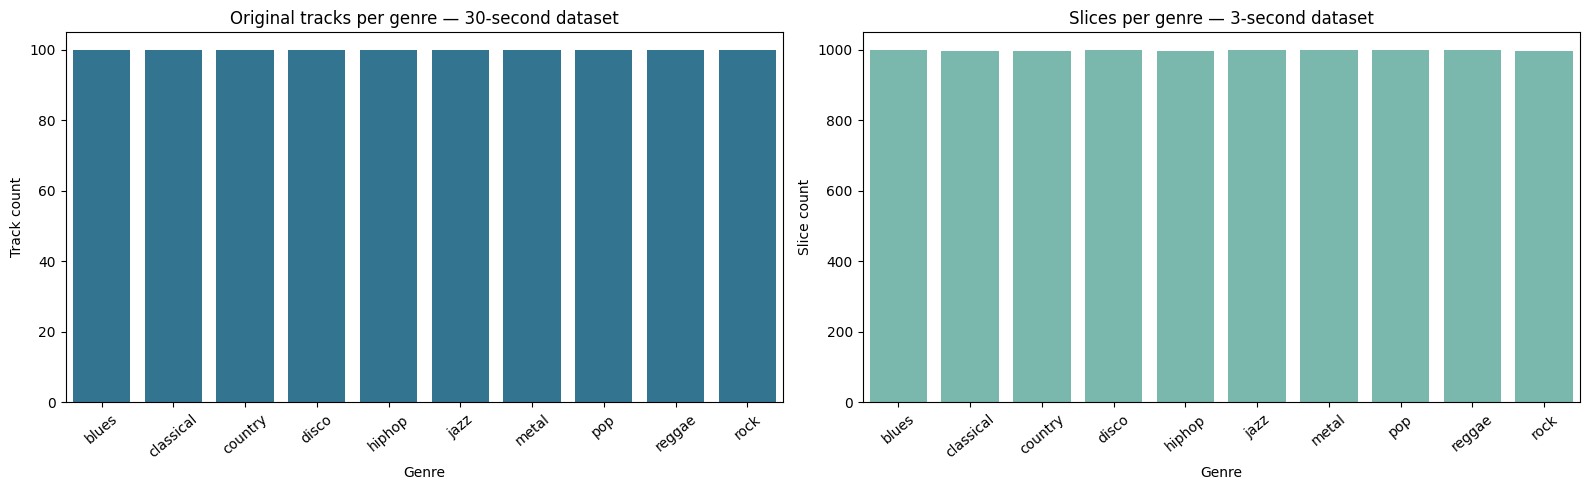

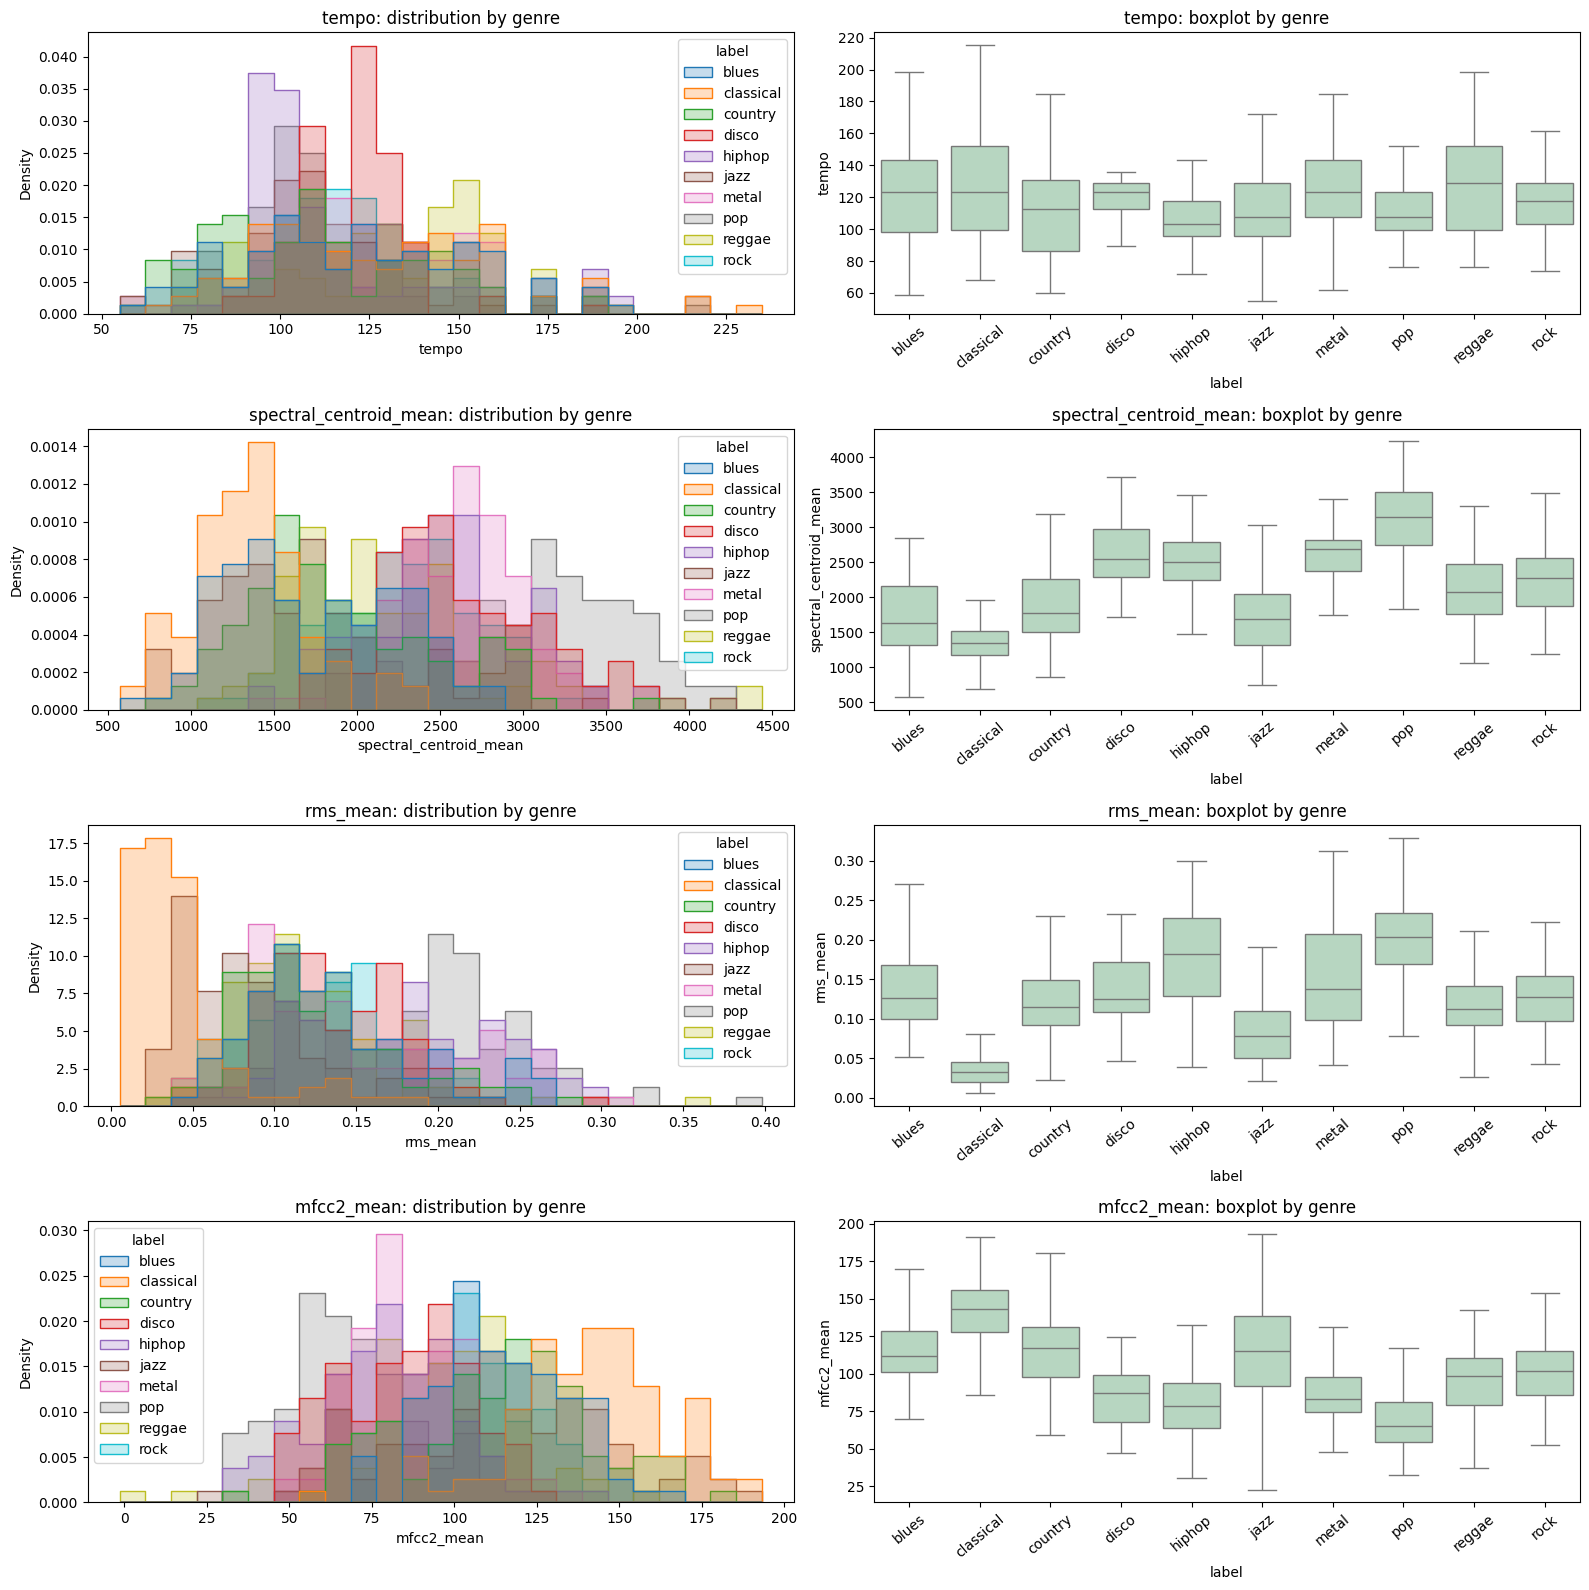


Top 15 EDA-ranked features:


,feature,anova_f_score,p_value
0,chroma_stft_mean,176.453282,7.683150e-199
17,mfcc1_mean,130.371835,2.494661e-161
6,spectral_bandwidth_mean,116.601879,9.982752e-149
8,rolloff_mean,110.871317,2.939032e-143
4,spectral_centroid_mean,97.484924,6.437171e-130
23,mfcc4_mean,83.868555,1.887743e-115
19,mfcc2_mean,83.189909,1.053923e-114
5,spectral_centroid_var,82.134648,1.546188e-113
15,perceptr_var,80.388712,1.358291e-111
2,rms_mean,74.194652,1.485967e-104


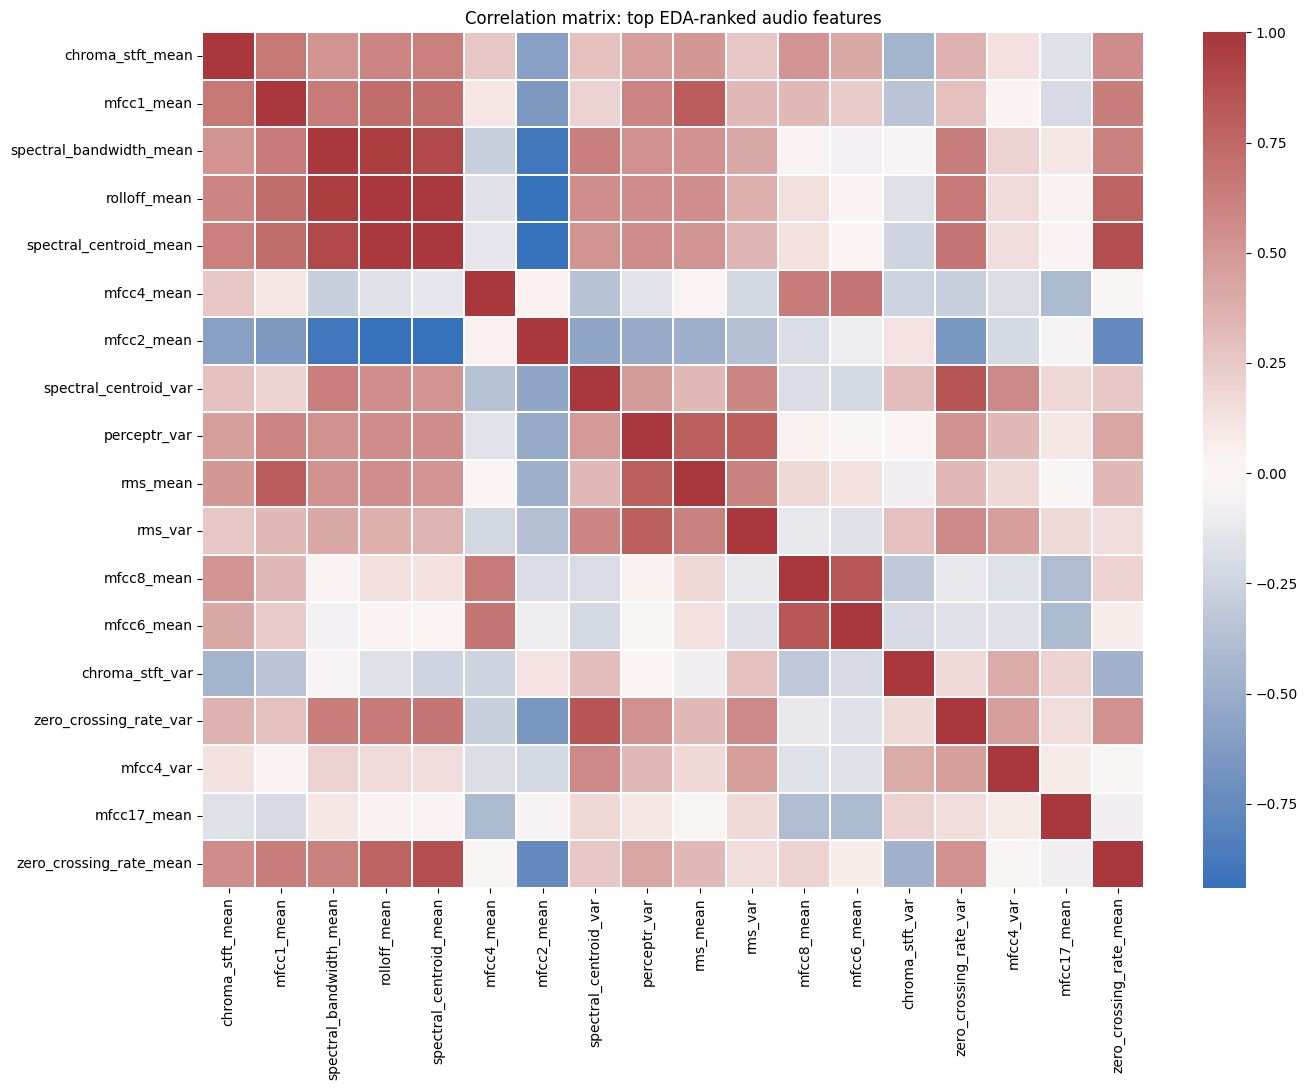

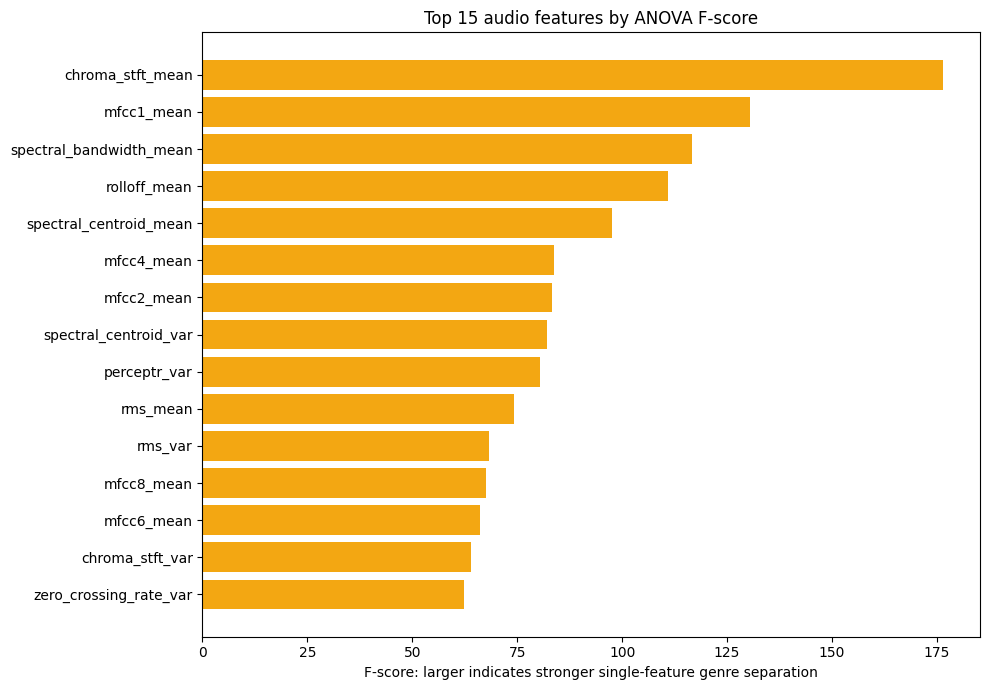

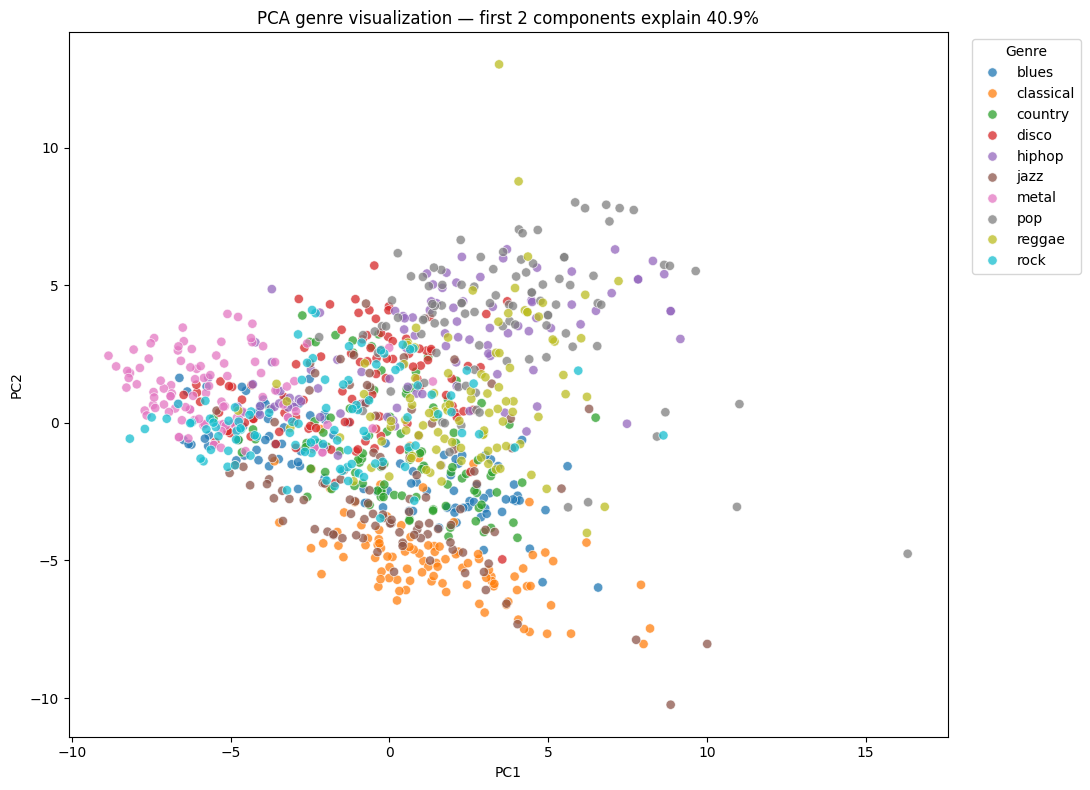

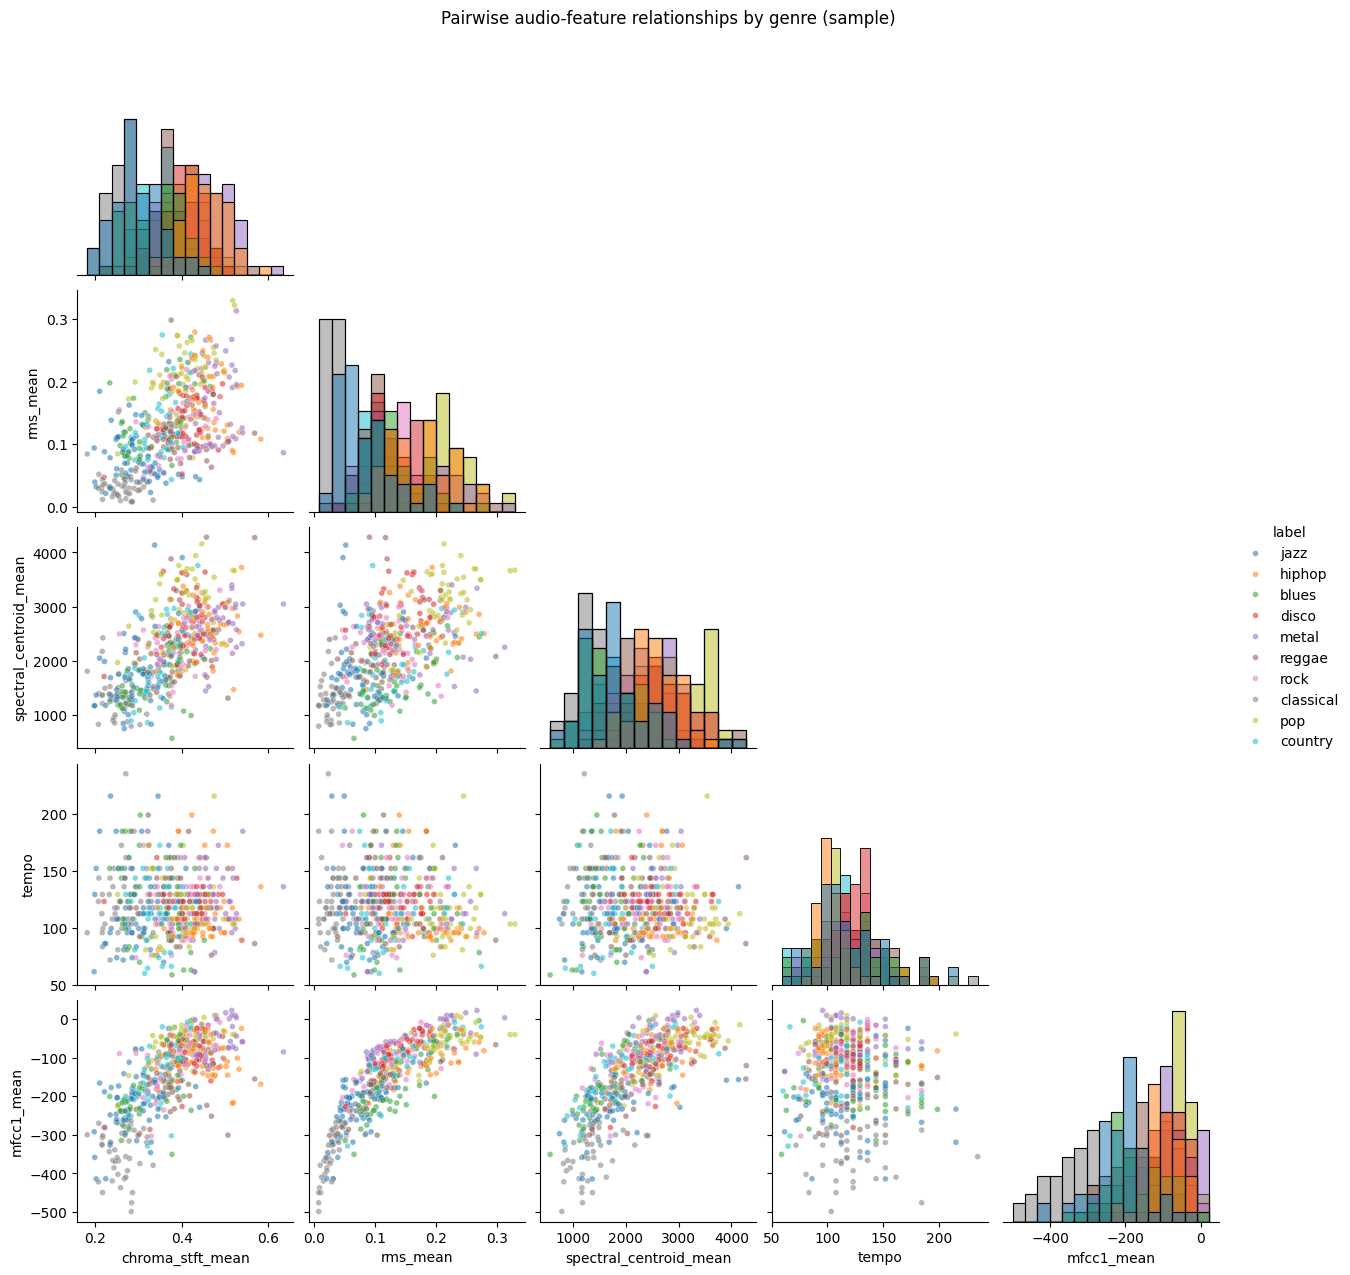


Part 1 complete.
Database, EDA figures, and reports are in: /content/outputs/part1
The source ZIP files were read only; they were not modified.


In [ ]:
# IDC409 MUSIC GENRE CLASSIFICATION — PART 1
#This part loads the 3-second and 30-second feature datasets for all 10 genres. It checks the data, counts tracks and slices per genre, and explores audio-feature distributions, correlations, and genre patterns. This helps us understand the dataset before training models.
# Uses the supplied pre-extracted feature CSVs.
# Supports all 10 GTZAN genres.

DATA_DIR = Path("/content")
OUTPUT_DIR = Path("/content/outputs/part1")
DB_PATH = OUTPUT_DIR / "music_genre.db"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

path_30 = DATA_DIR / "features_30_sec.csv.zip"
path_3 = DATA_DIR / "features_3_sec.csv.zip"

for path in [path_30, path_3]:
    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find {path}. Upload both dataset ZIP files in Cell 1."
        )

# Read the CSV inside each ZIP without extracting or changing the source files.
df30 = pd.read_csv(path_30, compression="zip")
df3 = pd.read_csv(path_3, compression="zip")

# Create the original-song ID. The 3-second CSV has multiple slices per song.
df30["track_id"] = df30["filename"].astype(str).str.replace(
    r"\.wav$", "", regex=True
)
df3["track_id"] = df3["filename"].astype(str).str.replace(
    r"\.\d+\.wav$", "", regex=True
)

# Basic checks and summary.
required_columns = {"filename", "label", "track_id"}
for name, data in [("30-second", df30), ("3-second", df3)]:
    missing_columns = required_columns - set(data.columns)
    if missing_columns:
        raise ValueError(f"{name} data is missing columns: {missing_columns}")
    if data.empty:
        raise ValueError(f"{name} dataset is empty.")

print("30-second dataset shape:", df30.shape)
print("3-second dataset shape:", df3.shape)
print("30-second unique tracks:", df30["track_id"].nunique())
print("3-second unique tracks:", df3["track_id"].nunique())
print("\nMissing cells:")
print("30-second:", int(df30.isna().sum().sum()))
print("3-second:", int(df3.isna().sum().sum()))
print("\nDuplicate full rows:")
print("30-second:", int(df30.duplicated().sum()))
print("3-second:", int(df3.duplicated().sum()))

# Show the 10 genres and their counts.
print("\nOriginal tracks per genre:")
display(
    df30.groupby("label")["track_id"]
    .nunique()
    .sort_index()
    .rename("original_track_count")
    .to_frame()
)

print("\n3-second slices per genre:")
display(
    df3["label"]
    .value_counts()
    .sort_index()
    .rename("slice_count")
    .to_frame()
)

# Record how many slices each original song has.
slices_per_track = df3.groupby("track_id").size()
print("\nNumber of 3-second slices per original track:")
print(slices_per_track.value_counts().sort_index().to_string())

# Numeric audio features. "length" is metadata, not a model feature.
feature_cols = [
    col for col in df30.select_dtypes(include=np.number).columns
    if col != "length"
]
print(f"\nNumeric audio feature columns: {len(feature_cols)}")
print("Genres:", sorted(df30["label"].astype(str).unique()))

# Save datasets and a genre-count summary into SQLite.
summary_rows = []
for table_name, data in [
    ("features_30_sec", df30),
    ("features_3_sec", df3),
]:
    for genre, group in data.groupby("label"):
        summary_rows.append({
            "dataset": table_name,
            "genre": genre,
            "original_track_count": group["track_id"].nunique(),
            "row_or_slice_count": len(group),
        })

summary = pd.DataFrame(summary_rows)

with sqlite3.connect(DB_PATH) as connection:
    df30.to_sql("features_30_sec", connection, if_exists="replace", index=False)
    df3.to_sql("features_3_sec", connection, if_exists="replace", index=False)
    summary.to_sql("genre_summary", connection, if_exists="replace", index=False)

    # Read back from SQLite to show that the database was written successfully.
    db_summary = pd.read_sql_query(
        "SELECT * FROM genre_summary ORDER BY dataset, genre",
        connection,
    )

summary.to_csv(OUTPUT_DIR / "genre_summary.csv", index=False)
print(f"\nSQLite database written: {DB_PATH}")
display(db_summary)

# Class balance: original songs and 3-second slices.
track_counts = (
    df30.groupby("label")["track_id"].nunique().sort_index()
)
slice_counts = df3["label"].value_counts().reindex(track_counts.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=track_counts.index, y=track_counts.values, ax=axes[0], color="#247ba0")
axes[0].set_title("Original tracks per genre — 30-second dataset")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Track count")
axes[0].tick_params(axis="x", rotation=40)

sns.barplot(x=slice_counts.index, y=slice_counts.values, ax=axes[1], color="#70c1b3")
axes[1].set_title("Slices per genre — 3-second dataset")
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Slice count")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_class_and_slice_counts.png", dpi=180)
plt.show()
plt.close()

# Distribution histograms and boxplots for selected audio features.
distribution_features = [
    col for col in [
        "tempo",
        "spectral_centroid_mean",
        "rms_mean",
        "mfcc2_mean",
    ]
    if col in df30.columns
]

fig, axes = plt.subplots(
    len(distribution_features), 2,
    figsize=(16, 4 * len(distribution_features))
)
if len(distribution_features) == 1:
    axes = np.array([axes])

for row, feature in enumerate(distribution_features):
    sns.histplot(
        data=df30, x=feature, hue="label",
        bins=25, element="step", stat="density",
        common_norm=False, ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{feature}: distribution by genre")

    sns.boxplot(
        data=df30, x="label", y=feature,
        order=sorted(df30["label"].astype(str).unique()),
        showfliers=False, ax=axes[row, 1], color="#b2dbbf",
    )
    axes[row, 1].set_title(f"{feature}: boxplot by genre")
    axes[row, 1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_feature_histograms_and_boxplots.png", dpi=180)
plt.show()
plt.close()

# Descriptive ANOVA feature ranking for EDA.
# This ranking is for exploration. Part 2 fits feature selection only on training data.
X_eda = df30[feature_cols].replace([np.inf, -np.inf], np.nan)
X_eda = X_eda.fillna(X_eda.median(numeric_only=True))
y_eda = df30["label"].astype(str)

f_scores, p_values = f_classif(X_eda, y_eda)
ranking = pd.DataFrame({
    "feature": feature_cols,
    "anova_f_score": f_scores,
    "p_value": p_values,
}).replace([np.inf, -np.inf], np.nan)
ranking = ranking.sort_values("anova_f_score", ascending=False)
ranking.to_csv(OUTPUT_DIR / "feature_reduction_anova_ranking.csv", index=False)

print("\nTop 15 EDA-ranked features:")
display(ranking.head(15))

# Correlation matrix for the top 18 EDA-ranked features.
top_features = ranking["feature"].head(18).tolist()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    df30[top_features].corr(),
    cmap="vlag",
    center=0,
    linewidths=0.2,
    ax=ax,
)
ax.set_title("Correlation matrix: top EDA-ranked audio features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_feature_correlation_matrix.png", dpi=180)
plt.show()
plt.close()

# Feature-ranking chart, useful for discussing feature reduction.
top15 = ranking.head(15).sort_values("anova_f_score")
plt.figure(figsize=(10, 7))
plt.barh(top15["feature"], top15["anova_f_score"], color="#f3a712")
plt.title("Top 15 audio features by ANOVA F-score")
plt.xlabel("F-score: larger indicates stronger single-feature genre separation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_feature_ranking.png", dpi=180)
plt.show()
plt.close()

# PCA plot: descriptive visualization of the 30-second tracks.
# This PCA is for EDA only, not used to evaluate the models.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_eda)
pca = PCA(n_components=2, random_state=409)
coordinates = pca.fit_transform(X_scaled)

pca_data = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
pca_data["label"] = df30["label"].astype(str).values

plt.figure(figsize=(11, 8))
sns.scatterplot(
    data=pca_data, x="PC1", y="PC2",
    hue="label", palette="tab10", alpha=0.75, s=45,
)
variance = pca.explained_variance_ratio_.sum() * 100
plt.title(f"PCA genre visualization — first 2 components explain {variance:.1f}%")
plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_pca_genres.png", dpi=180)
plt.show()
plt.close()

# Pairwise feature relationships, with histograms on the diagonal.
pair_features = [
    col for col in [
        "chroma_stft_mean",
        "rms_mean",
        "spectral_centroid_mean",
        "tempo",
        "mfcc1_mean",
    ]
    if col in df30.columns
]

if len(pair_features) >= 2:
    pair_data = df30[pair_features + ["label"]].sample(
        n=min(500, len(df30)), random_state=409
    )
    pair_plot = sns.pairplot(
        pair_data,
        vars=pair_features,
        hue="label",
        diag_kind="hist",
        corner=True,
        plot_kws={"alpha": 0.55, "s": 18},
    )
    pair_plot.fig.suptitle(
        "Pairwise audio-feature relationships by genre (sample)",
        y=1.02,
    )
    pair_plot.fig.savefig(
        OUTPUT_DIR / "06_pairwise_feature_relationships.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(pair_plot.fig)

# Save a plain-language guide to the supplied feature names.
feature_meanings = {
    "chroma_stft": "Pitch-class energy profile, summarized over time.",
    "rms": "Root-mean-square energy; a rough measure of signal intensity.",
    "spectral_centroid": "Spectral center of mass, often associated with brightness.",
    "spectral_bandwidth": "Spread of spectral energy around its centroid.",
    "rolloff": "Frequency below which most spectral energy is concentrated.",
    "zero_crossing_rate": "How often the waveform changes sign.",
    "harmony": "Summary of the harmonic component in the supplied feature table.",
    "perceptr": "Legacy GTZAN percussive-component field name.",
    "tempo": "Estimated musical tempo in beats per minute.",
    "mfcc": "Compact descriptors of spectral timbre.",
}

dictionary_rows = []
for feature in feature_cols:
    if feature.endswith("_mean"):
        family, statistic = feature[:-5], "mean across frames"
    elif feature.endswith("_var"):
        family, statistic = feature[:-4], "variance across frames"
    else:
        family, statistic = feature, "single estimate"

    if family.startswith("mfcc"):
        family = "mfcc"

    dictionary_rows.append({
        "feature": feature,
        "summary_statistic": statistic,
        "plain_language_meaning": feature_meanings.get(
            family, "Audio feature summary from the supplied GTZAN table."
        ),
    })

pd.DataFrame(dictionary_rows).to_csv(
    OUTPUT_DIR / "feature_dictionary.csv", index=False
)

# Save a text report with row counts, missing values and track/slice counts.
report_lines = [
    "IDC409 MUSIC GENRE CLASSIFICATION — PART 1 DATA REPORT",
    "",
    f"30-second rows: {len(df30)}",
    f"3-second rows: {len(df3)}",
    f"30-second original tracks: {df30['track_id'].nunique()}",
    f"3-second original tracks: {df3['track_id'].nunique()}",
    f"Numeric audio features: {len(feature_cols)}",
    f"30-second missing cells: {int(df30.isna().sum().sum())}",
    f"3-second missing cells: {int(df3.isna().sum().sum())}",
    f"30-second duplicate rows: {int(df30.duplicated().sum())}",
    f"3-second duplicate rows: {int(df3.duplicated().sum())}",
    "",
    "Important: 3-second rows are slices from original songs.",
    "Part 2 splits by track_id so slices from one song cannot appear in both train and test.",
]
(OUTPUT_DIR / "data_quality_report.txt").write_text(
    "\n".join(report_lines), encoding="utf-8"
)

print("\nPart 1 complete.")
print(f"Database, EDA figures, and reports are in: {OUTPUT_DIR}")
print("The source ZIP files were read only; they were not modified.")

Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
30-second rows: 1000
3-second rows: 9990
Original tracks: 1000

Track split: train=640, validation=160, test=200
No original track is shared across the splits.
30_sec: validation fitting Logistic Regression
30_sec: validation fitting KNN
30_sec: validation fitting SVM (RBF)
30_sec: validation fitting Random Forest
30_sec: validation fitting Boosted Trees
30_sec: validation fitting Neural Network (MLP)
30_sec: validation fitting SVM (RBF, 15 selected features)
30_sec: validation fitting Logistic Regression (15 selected features)

30_sec selected by validation macro-F1: Neural Network (MLP)
30_sec: final test fitting Logistic Regression
30_sec: final test fitting KNN
30_sec: final test fitting SVM (RBF)
30_sec: final test fitting Random Forest
30_sec: final test fitting Boosted Trees
30_sec: final test fitting Neural Network (MLP)
30_sec: final test fitting SVM (RBF, 15 selected feature

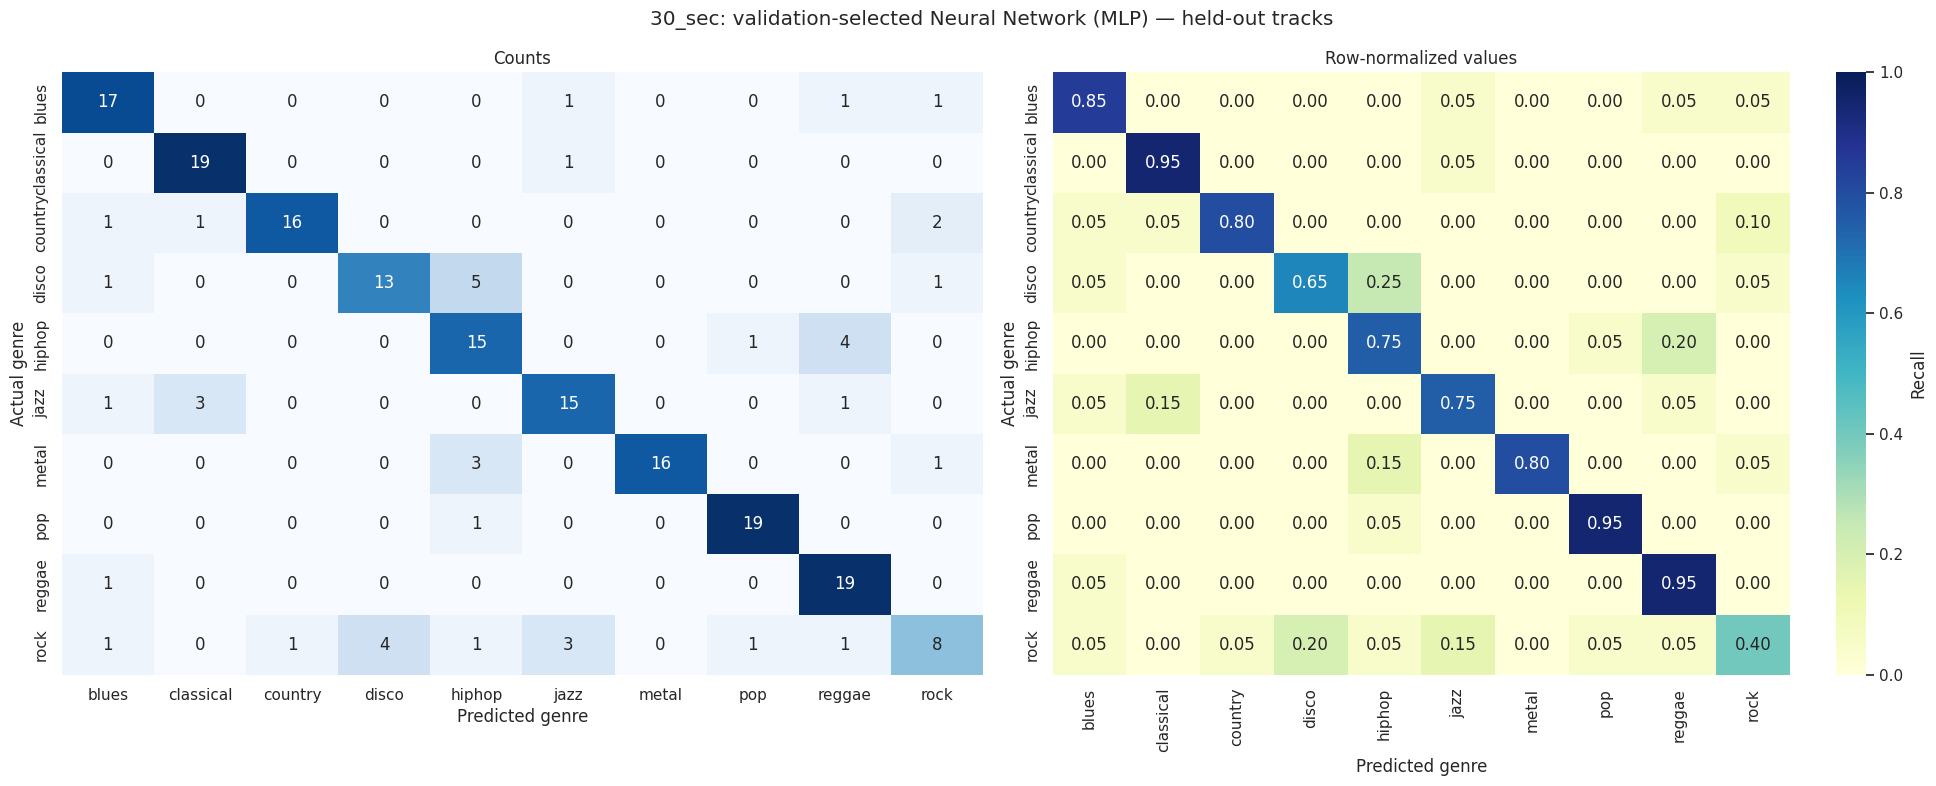

3_sec: validation fitting Logistic Regression
3_sec: validation fitting KNN
3_sec: validation fitting SVM (RBF)
3_sec: validation fitting Random Forest
3_sec: validation fitting Boosted Trees
3_sec: validation fitting Neural Network (MLP)
3_sec: validation fitting SVM (RBF, 15 selected features)
3_sec: validation fitting Logistic Regression (15 selected features)

3_sec selected by validation macro-F1: SVM (RBF)
3_sec: final test fitting Logistic Regression
3_sec: final test fitting KNN
3_sec: final test fitting SVM (RBF)
3_sec: final test fitting Random Forest
3_sec: final test fitting Boosted Trees
3_sec: final test fitting Neural Network (MLP)
3_sec: final test fitting SVM (RBF, 15 selected features)
3_sec: final test fitting Logistic Regression (15 selected features)


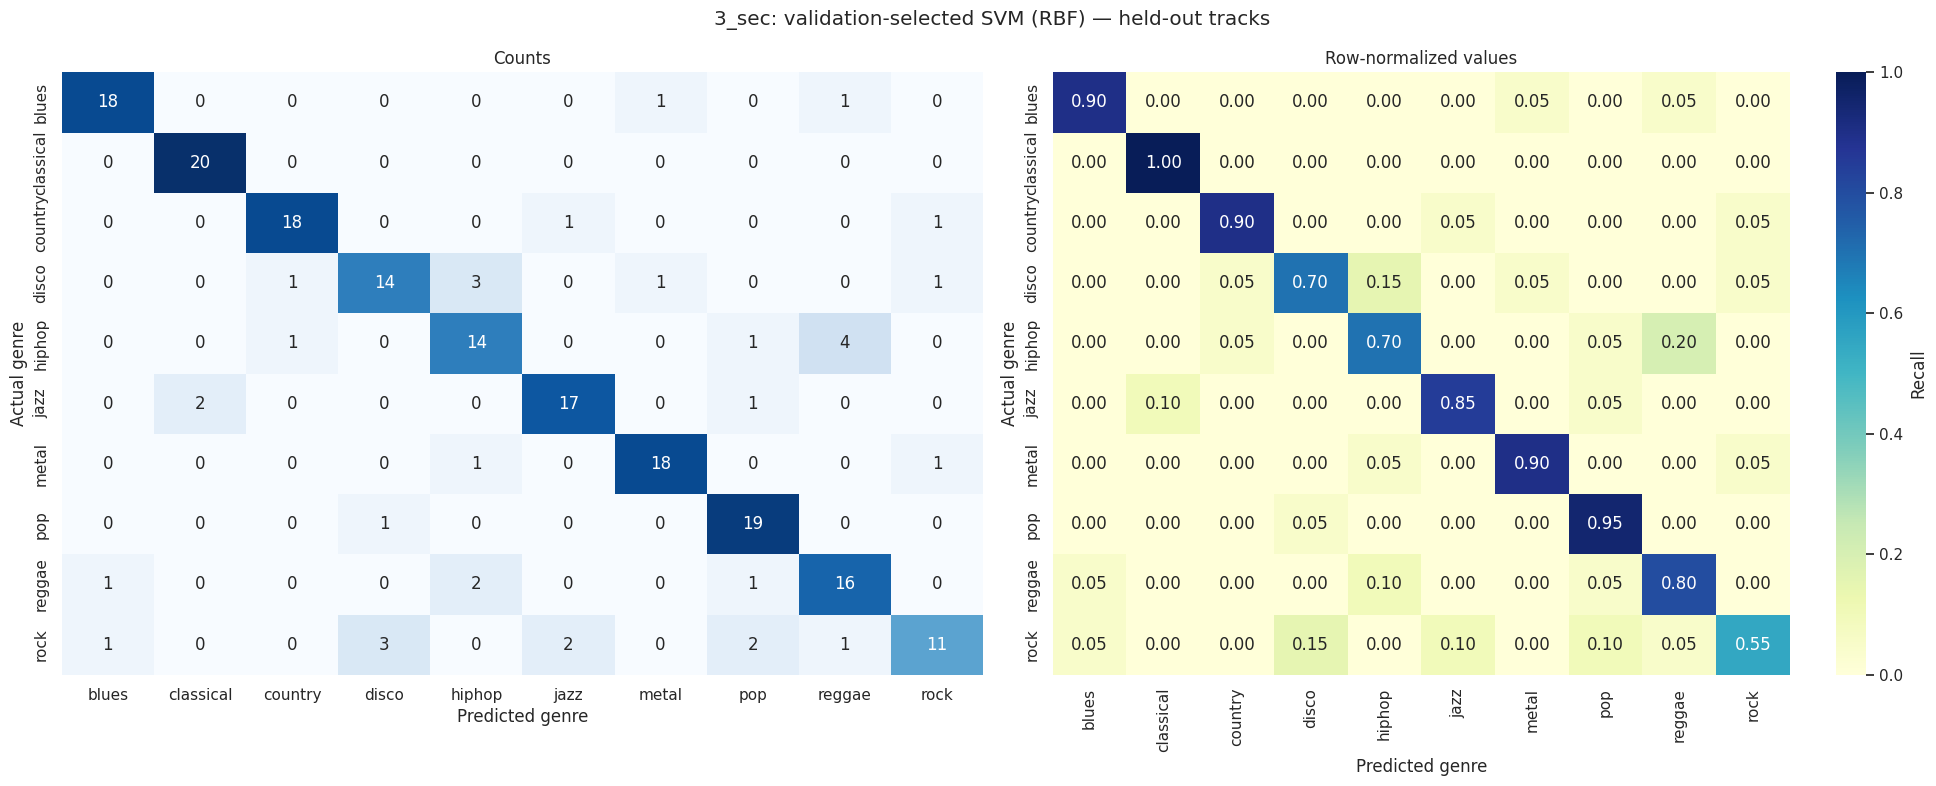


Validation model comparison (used to select each final model):


,dataset,model,accuracy,macro_f1,weighted_f1
0,30_sec,Neural Network (MLP),0.71875,0.720385,0.720385
1,30_sec,SVM (RBF),0.71875,0.718867,0.718867
2,30_sec,Boosted Trees,0.70625,0.707371,0.707371
3,30_sec,Random Forest,0.67500,0.674219,0.674219
4,30_sec,Logistic Regression,0.65000,0.655807,0.655807
5,30_sec,"SVM (RBF, 15 selected features)",0.63750,0.638913,0.638913
6,30_sec,KNN,0.60000,0.602016,0.602016
7,30_sec,Logistic Regression (15 selected features),0.59375,0.591526,0.591526
8,3_sec,SVM (RBF),0.80625,0.806001,0.806001
9,3_sec,Boosted Trees,0.78125,0.781823,0.781823



Held-out test comparison (track-level):


,dataset,model,selected_by_validation,accuracy,macro_f1,weighted_f1
3,30_sec,SVM (RBF),False,0.800,0.794155,0.794155
0,30_sec,Neural Network (MLP),True,0.785,0.780413,0.780413
5,30_sec,Boosted Trees,False,0.770,0.767348,0.767348
4,30_sec,Random Forest,False,0.755,0.747612,0.747612
1,30_sec,Logistic Regression,False,0.740,0.735709,0.735709
2,30_sec,KNN,False,0.730,0.727958,0.727958
6,30_sec,"SVM (RBF, 15 selected features)",False,0.720,0.710458,0.710458
7,30_sec,Logistic Regression (15 selected features),False,0.645,0.638482,0.638482
12,3_sec,Boosted Trees,False,0.840,0.836674,0.836674
13,3_sec,Neural Network (MLP),False,0.835,0.835921,0.835921


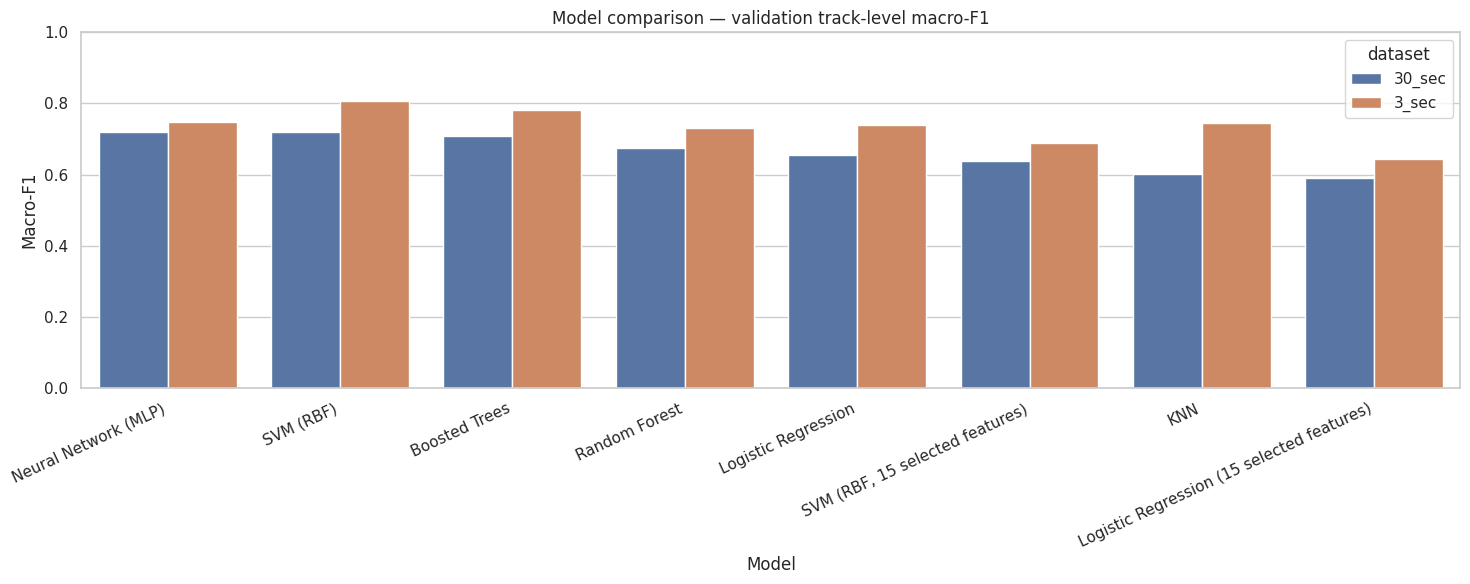

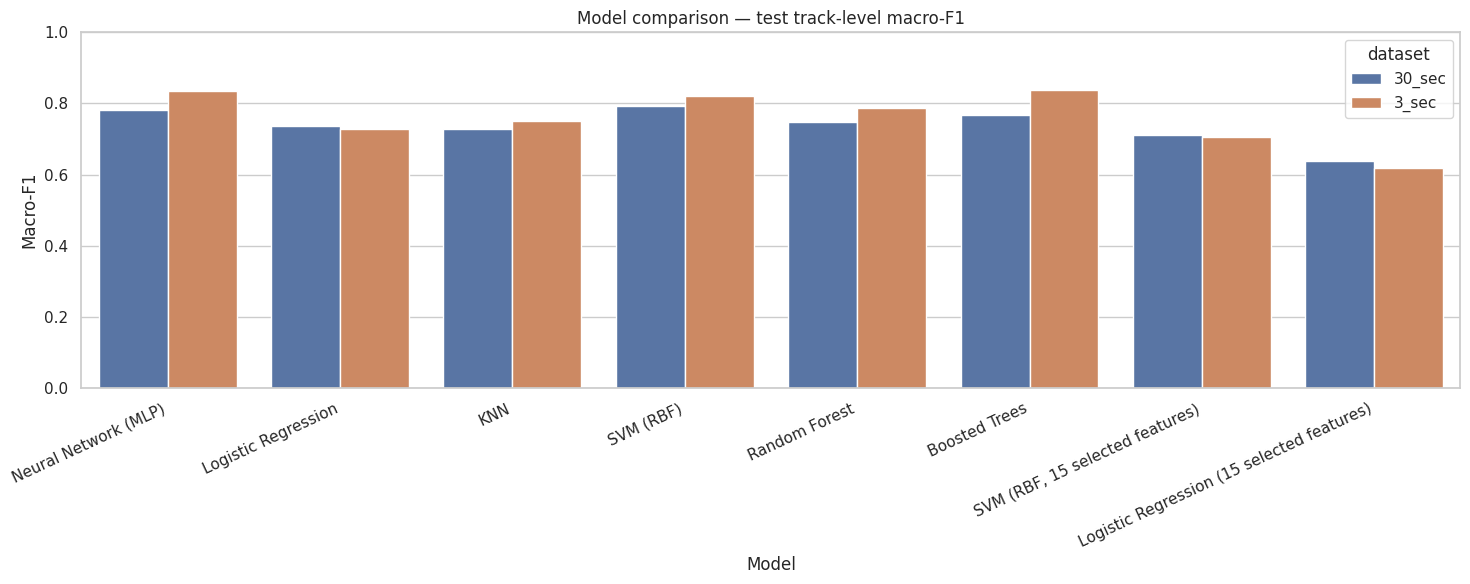


Part 2 complete. Results and trained models are in: /content/outputs/part2


In [ ]:
# PART 2 — Model comparison and track-level evaluation
#This part trains and compares machine-learning classifiers using audio features. It uses a track-level split so slices from the same original song do not appear in both training and test data. Validation results are used to select a model; the held-out test set is reserved for final evaluation.
# Run after Part 1 in the same Colab runtime.

from pathlib import Path
import sqlite3
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 409
DB_PATH = Path("/content/outputs/part1/music_genre.db")
OUTPUT_DIR = Path("/content/outputs/part2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DB_PATH}. Run Part 1 first in this Colab runtime."
    )

# Load both datasets from the Part 1 SQLite database.
with sqlite3.connect(DB_PATH) as connection:
    data_30 = pd.read_sql_query("SELECT * FROM features_30_sec", connection)
    data_3 = pd.read_sql_query("SELECT * FROM features_3_sec", connection)

genre_labels = sorted(data_30["label"].astype(str).unique().tolist())
print("Genres:", genre_labels)
print("30-second rows:", len(data_30))
print("3-second rows:", len(data_3))
print("Original tracks:", data_30["track_id"].nunique())

# Split original tracks first, so slices from one song cannot leak across splits.
tracks = data_30[["track_id", "label"]].drop_duplicates("track_id")

trainval_tracks, test_tracks = train_test_split(
    tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=tracks["label"],
)
train_tracks, validation_tracks = train_test_split(
    trainval_tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=trainval_tracks["label"],
)

train_ids = set(train_tracks["track_id"].astype(str))
validation_ids = set(validation_tracks["track_id"].astype(str))
test_ids = set(test_tracks["track_id"].astype(str))
trainval_ids = train_ids | validation_ids

assert not (train_ids & validation_ids)
assert not (train_ids & test_ids)
assert not (validation_ids & test_ids)

print(
    f"\nTrack split: train={len(train_ids)}, "
    f"validation={len(validation_ids)}, test={len(test_ids)}"
)
print("No original track is shared across the splits.")

# Candidate models. Scaling is included for models that need it.
def create_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                C=1.0, max_iter=2500, class_weight="balanced"
            )),
        ]),
        "KNN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", KNeighborsClassifier(
                n_neighbors=11, weights="distance", p=2
            )),
        ]),
        "SVM (RBF)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", SVC(
                C=3.0, kernel="rbf", probability=True,
                class_weight="balanced", random_state=SEED
            )),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=250,
                min_samples_leaf=2,
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED,
            )),
        ]),
        "Boosted Trees": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingClassifier(
                learning_rate=0.08,
                max_iter=160,
                max_leaf_nodes=20,
                l2_regularization=1.0,
                random_state=SEED,
            )),
        ]),
        "Neural Network (MLP)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(128, 64),
                activation="relu",
                alpha=0.01,
                learning_rate_init=0.001,
                max_iter=180,
                random_state=SEED,
            )),
        ]),
        # Feature selection is fitted inside each model pipeline.
        "SVM (RBF, 15 selected features)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif, k=15)),
            ("model", SVC(
                C=3.0, kernel="rbf", probability=True,
                class_weight="balanced", random_state=SEED
            )),
        ]),
        "Logistic Regression (15 selected features)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif, k=15)),
            ("model", LogisticRegression(
                C=1.0, max_iter=2500, class_weight="balanced"
            )),
        ]),
    }


def get_rows_and_xy(data, track_ids, feature_names):
    rows = data[data["track_id"].astype(str).isin(track_ids)].copy()
    X = rows[feature_names].replace([np.inf, -np.inf], np.nan)
    y = rows["label"].astype(str)
    return rows, X, y


def predict_tracks(model, rows, X, labels):
    """Average 3-second segment probabilities to get one prediction per song."""
    probabilities = model.predict_proba(X)
    model_classes = list(model.classes_)

    probability_frame = pd.DataFrame(
        probabilities, columns=model_classes, index=rows.index
    ).reindex(columns=labels, fill_value=0.0)

    probability_frame["track_id"] = rows["track_id"].astype(str).values
    probability_frame["true_label"] = rows["label"].astype(str).values

    track_probabilities = probability_frame.groupby("track_id")[labels].mean()
    true_labels = (
        probability_frame.groupby("track_id")["true_label"]
        .first()
        .reindex(track_probabilities.index)
    )
    predicted_labels = track_probabilities.idxmax(axis=1)

    return true_labels.tolist(), predicted_labels.tolist(), track_probabilities


def score_predictions(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, labels=genre_labels,
            average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, labels=genre_labels,
            average="weighted", zero_division=0
        ),
    }


def save_confusion_matrix(y_true, y_pred, duration, model_name):
    matrix = confusion_matrix(y_true, y_pred, labels=genre_labels)
    row_sums = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(
        matrix,
        row_sums,
        out=np.zeros_like(matrix, dtype=float),
        where=row_sums != 0,
    )

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues",
        xticklabels=genre_labels, yticklabels=genre_labels,
        ax=axes[0], cbar=False,
    )
    axes[0].set_title("Counts")
    axes[0].set_xlabel("Predicted genre")
    axes[0].set_ylabel("Actual genre")

    sns.heatmap(
        normalized, annot=True, fmt=".2f", cmap="YlGnBu",
        xticklabels=genre_labels, yticklabels=genre_labels,
        vmin=0, vmax=1, ax=axes[1],
        cbar_kws={"label": "Recall"},
    )
    axes[1].set_title("Row-normalized values")
    axes[1].set_xlabel("Predicted genre")
    axes[1].set_ylabel("Actual genre")

    fig.suptitle(
        f"{duration}: validation-selected {model_name} — held-out tracks"
    )
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{duration}_confusion_matrix.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def save_confusion_reflection(y_true, y_pred, duration, model_name):
    matrix = confusion_matrix(y_true, y_pred, labels=genre_labels)
    errors = []

    for i, actual in enumerate(genre_labels):
        row_total = matrix[i].sum()
        if row_total == 0:
            continue
        for j, predicted in enumerate(genre_labels):
            if i != j and matrix[i, j] > 0:
                errors.append(
                    (matrix[i, j], matrix[i, j] / row_total, actual, predicted)
                )

    errors.sort(reverse=True)
    lines = [
        f"Confusion reflection — {duration}",
        f"Validation-selected model: {model_name}",
        "",
        "Most frequent errors (actual genre -> predicted genre):",
    ]

    if errors:
        for count, rate, actual, predicted in errors[:5]:
            lines.append(
                f"{actual} -> {predicted}: {count} tracks ({rate:.1%} "
                f"of held-out {actual} tracks)"
            )
    else:
        lines.append("No off-diagonal errors on this held-out split.")

    lines.extend([
        "",
        "Reflection note:",
        "Use the EDA plots to discuss whether overlapping timbre, chroma,",
        "spectral brightness, or tempo patterns could help explain these errors.",
        "Present that explanation as a hypothesis; the confusion matrix alone",
        "does not prove why two genres were confused.",
    ])

    (OUTPUT_DIR / f"{duration}_confusion_reflection.txt").write_text(
        "\n".join(lines), encoding="utf-8"
    )


# Fit each candidate on train tracks, select by validation macro-F1,
# then refit on train + validation tracks for the final held-out test.
all_validation_results = []
all_test_results = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    excluded = {"filename", "label", "track_id", "length"}
    feature_names = [
        col for col in data.select_dtypes(include="number").columns
        if col not in excluded
    ]

    train_rows, X_train, y_train = get_rows_and_xy(
        data, train_ids, feature_names
    )
    validation_rows, X_validation, _ = get_rows_and_xy(
        data, validation_ids, feature_names
    )
    trainval_rows, X_trainval, y_trainval = get_rows_and_xy(
        data, trainval_ids, feature_names
    )
    test_rows, X_test, _ = get_rows_and_xy(
        data, test_ids, feature_names
    )

    validation_scores = []
    for model_name, model in create_models().items():
        print(f"{duration}: validation fitting {model_name}")
        model.fit(X_train, y_train)
        y_val, pred_val, _ = predict_tracks(
            model, validation_rows, X_validation, genre_labels
        )
        validation_scores.append({
            "dataset": duration,
            "model": model_name,
            **score_predictions(y_val, pred_val),
        })

    validation_table = pd.DataFrame(validation_scores).sort_values(
        ["macro_f1", "accuracy"], ascending=False
    )
    best_model_name = validation_table.iloc[0]["model"]
    all_validation_results.append(validation_table)

    print(f"\n{duration} selected by validation macro-F1: {best_model_name}")

    test_scores = []
    fitted_models = {}

    for model_name, model in create_models().items():
        print(f"{duration}: final test fitting {model_name}")
        model.fit(X_trainval, y_trainval)

        y_test, pred_test, track_probabilities = predict_tracks(
            model, test_rows, X_test, genre_labels
        )

        test_scores.append({
            "dataset": duration,
            "model": model_name,
            "selected_by_validation": model_name == best_model_name,
            **score_predictions(y_test, pred_test),
        })
        fitted_models[model_name] = (
            model, y_test, pred_test, track_probabilities
        )

    test_table = pd.DataFrame(test_scores).sort_values(
        "selected_by_validation", ascending=False
    )
    all_test_results.append(test_table)

    # Produce the final confusion matrix/report using the model chosen on validation.
    best_model, y_test, pred_test, track_probabilities = fitted_models[best_model_name]

    save_confusion_matrix(y_test, pred_test, duration, best_model_name)
    save_confusion_reflection(y_test, pred_test, duration, best_model_name)

    report = classification_report(
        y_test, pred_test, labels=genre_labels,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).transpose().to_csv(
        OUTPUT_DIR / f"{duration}_classification_report.csv"
    )
    (OUTPUT_DIR / f"{duration}_classification_report.txt").write_text(
        f"Dataset: {duration}\n"
        f"Selected using validation macro-F1: {best_model_name}\n\n"
        + classification_report(
            y_test, pred_test, labels=genre_labels, zero_division=0
        ),
        encoding="utf-8",
    )

    selected_features = feature_names
    if "select" in best_model.named_steps:
        selected_features = np.asarray(feature_names)[
            best_model.named_steps["select"].get_support()
        ].tolist()

    pd.DataFrame({"feature": selected_features}).to_csv(
        OUTPUT_DIR / f"{duration}_selected_model_features.csv",
        index=False,
    )

    # Save the trained model for Part 4's WAV upload classifier.
    joblib.dump(
        {
            "model": best_model,
            "features": feature_names,
            "selected_features": selected_features,
            "genres": genre_labels,
            "duration": duration,
            "selected_model": best_model_name,
        },
        OUTPUT_DIR / f"{duration}_best_model.joblib",
    )
    track_probabilities.to_csv(
        OUTPUT_DIR / f"{duration}_test_track_probabilities.csv"
    )

# Save the comparison tables.
validation_results = pd.concat(all_validation_results, ignore_index=True)
test_results = pd.concat(all_test_results, ignore_index=True)

validation_results.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv", index=False
)
test_results.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv", index=False
)

print("\nValidation model comparison (used to select each final model):")
display(
    validation_results.sort_values(
        ["dataset", "macro_f1"], ascending=[True, False]
    )
)

print("\nHeld-out test comparison (track-level):")
display(
    test_results.sort_values(
        ["dataset", "macro_f1"], ascending=[True, False]
    )
)

# Plot macro-F1 comparison for validation and held-out test.
for phase, results_table in [
    ("validation", validation_results),
    ("test", test_results),
]:
    plt.figure(figsize=(15, 6))
    sns.barplot(
        data=results_table,
        x="model",
        y="macro_f1",
        hue="dataset",
    )
    plt.title(f"Model comparison — {phase} track-level macro-F1")
    plt.xlabel("Model")
    plt.ylabel("Macro-F1")
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"model_comparison_{phase}_macro_f1.png",
        dpi=180,
    )
    plt.show()
    plt.close()

print(f"\nPart 2 complete. Results and trained models are in: {OUTPUT_DIR}")

Part 2.1: fitting 30_sec — Logistic Regression
Part 2.1: fitting 30_sec — KNN
Part 2.1: fitting 30_sec — SVM (RBF)
Part 2.1: fitting 30_sec — Random Forest
Part 2.1: fitting 30_sec — Boosted Trees
Part 2.1: fitting 30_sec — Neural Network (MLP)
Part 2.1: fitting 30_sec — SVM (RBF, 15 selected features)
Part 2.1: fitting 30_sec — Logistic Regression (15 selected features)


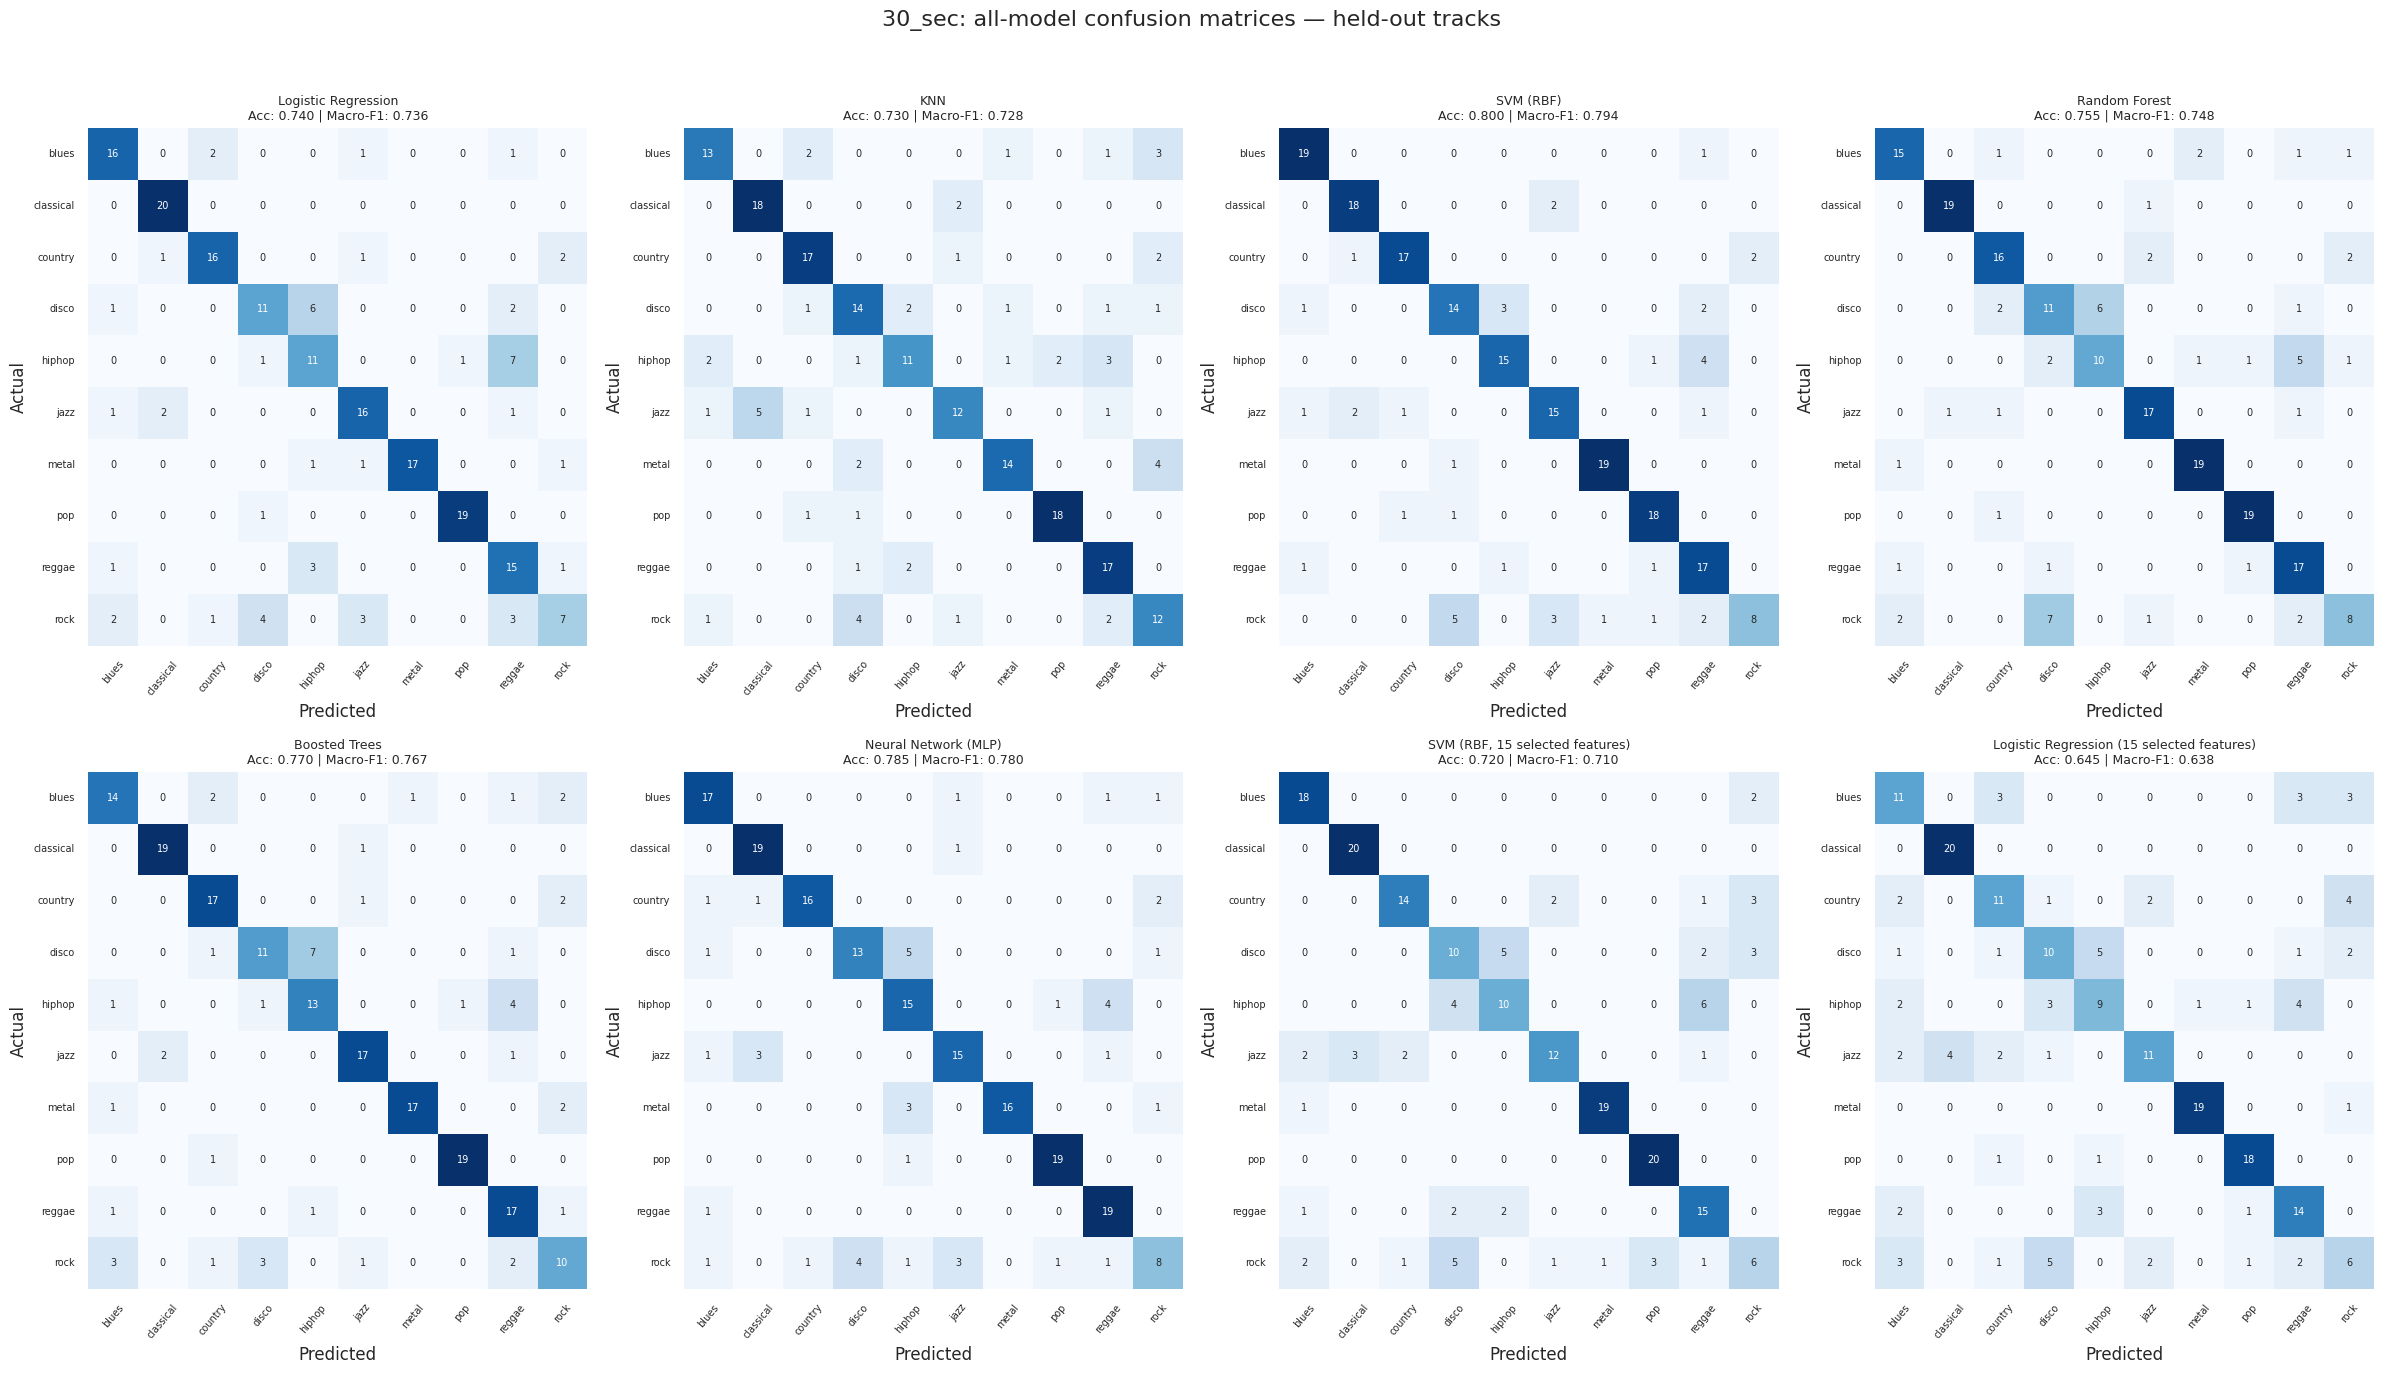

Part 2.1: fitting 3_sec — Logistic Regression
Part 2.1: fitting 3_sec — KNN
Part 2.1: fitting 3_sec — SVM (RBF)
Part 2.1: fitting 3_sec — Random Forest
Part 2.1: fitting 3_sec — Boosted Trees
Part 2.1: fitting 3_sec — Neural Network (MLP)
Part 2.1: fitting 3_sec — SVM (RBF, 15 selected features)
Part 2.1: fitting 3_sec — Logistic Regression (15 selected features)


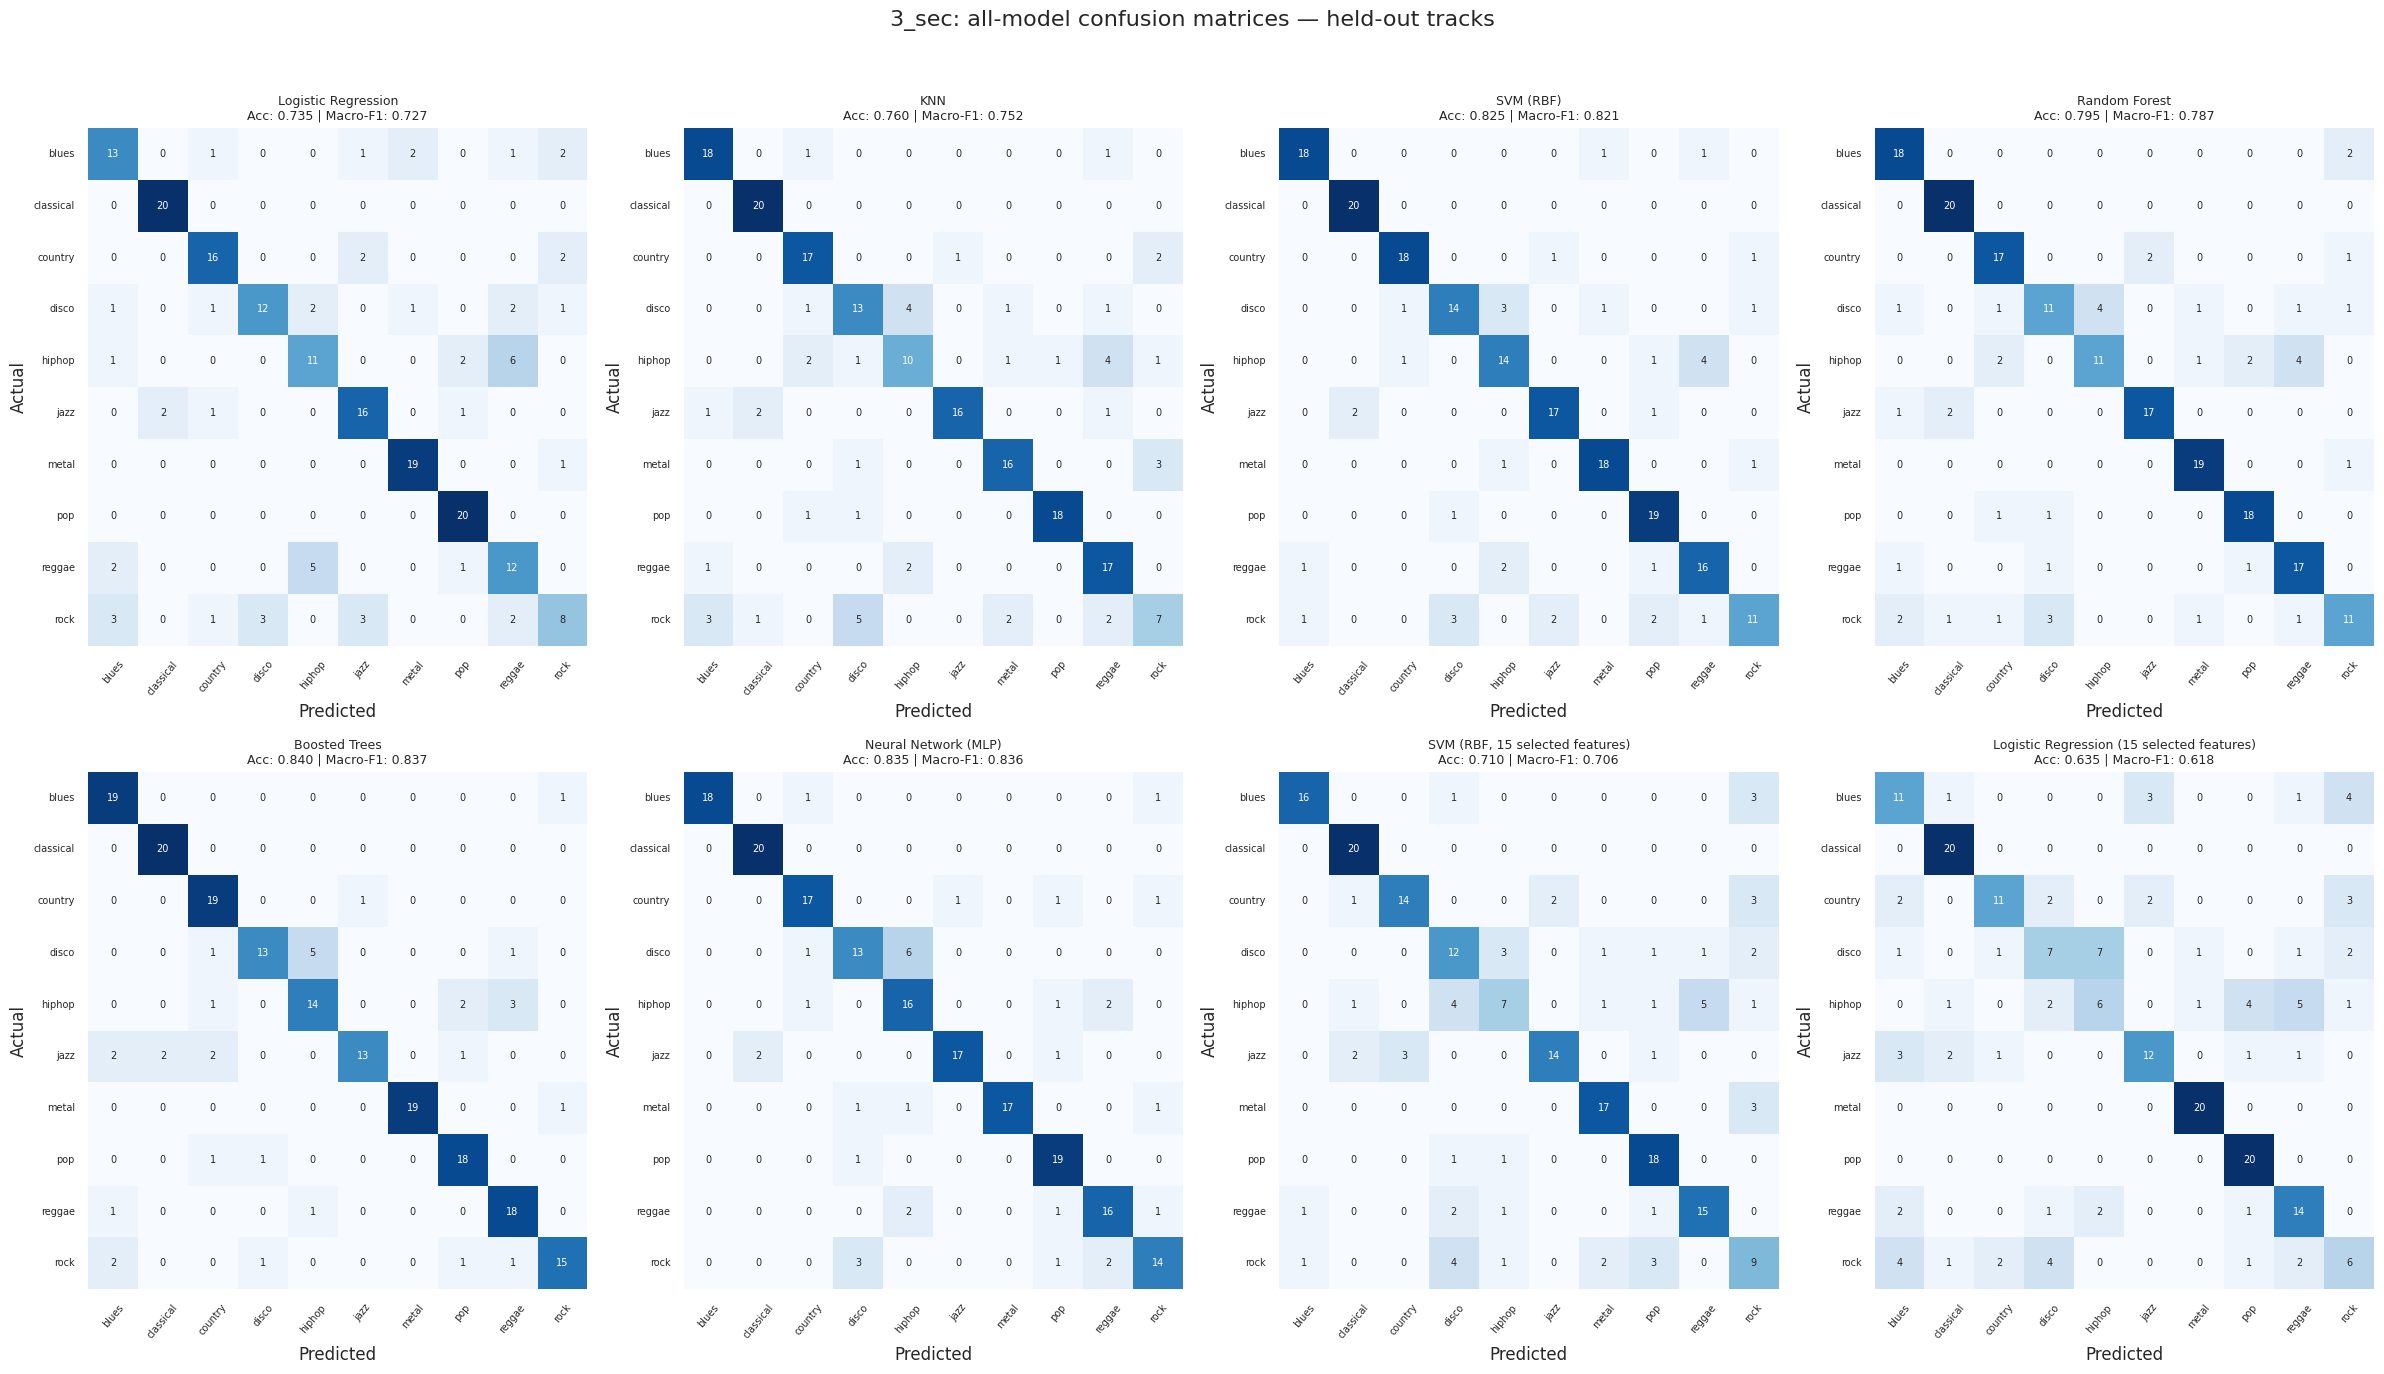


Part 2.1 held-out test comparison:


,dataset,model,accuracy,macro_f1,weighted_f1,held_out_tracks
2,30_sec,SVM (RBF),0.800,0.794155,0.794155,200
5,30_sec,Neural Network (MLP),0.785,0.780413,0.780413,200
4,30_sec,Boosted Trees,0.770,0.767348,0.767348,200
3,30_sec,Random Forest,0.755,0.747612,0.747612,200
0,30_sec,Logistic Regression,0.740,0.735709,0.735709,200
1,30_sec,KNN,0.730,0.727958,0.727958,200
6,30_sec,"SVM (RBF, 15 selected features)",0.720,0.710458,0.710458,200
7,30_sec,Logistic Regression (15 selected features),0.645,0.638482,0.638482,200
12,3_sec,Boosted Trees,0.840,0.836674,0.836674,200
13,3_sec,Neural Network (MLP),0.835,0.835921,0.835921,200


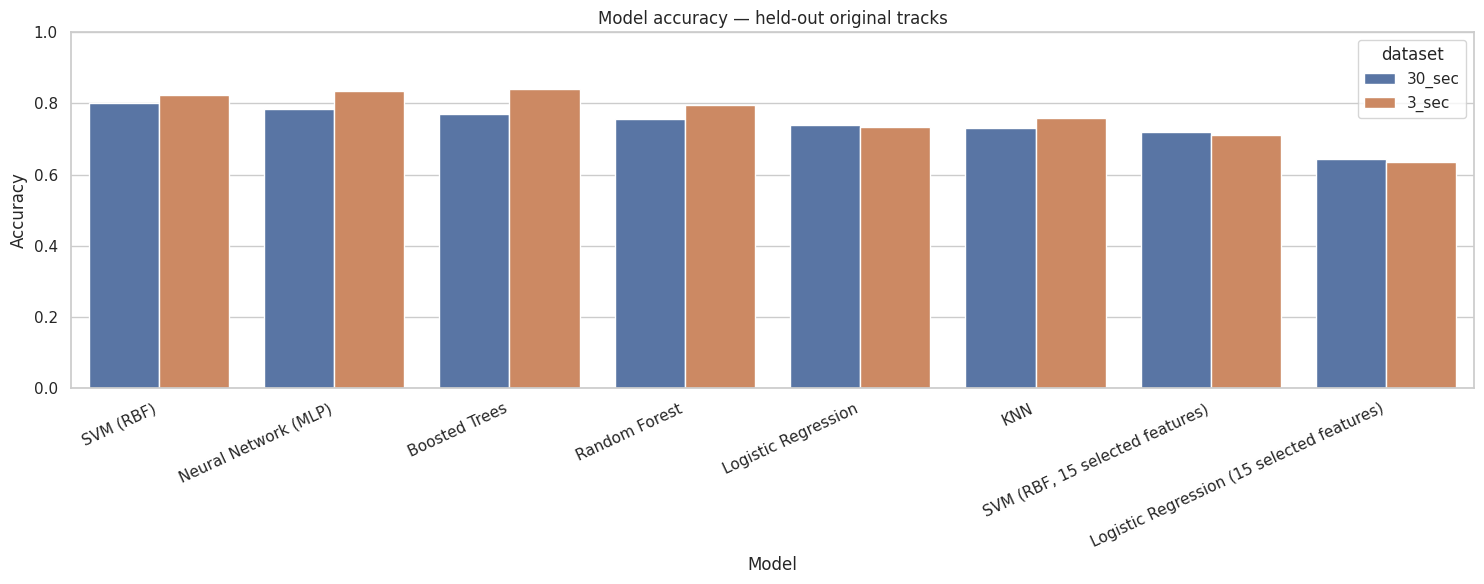

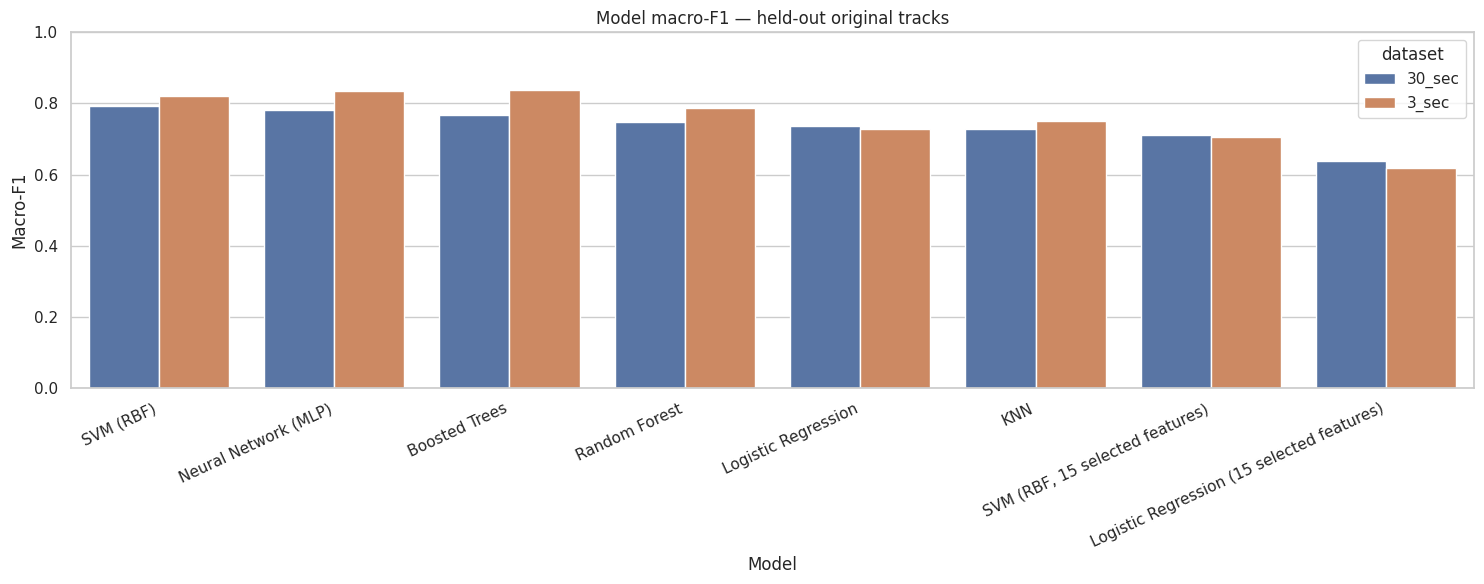


Part 2.1 complete. Files saved in: /content/outputs/part2_1


In [ ]:
# PART 2.1 — Detailed model comparison and confusion matrices
#This part compares model performance using accuracy, macro-F1, and confusion matrices. These results show both overall performance and which genres the models mix up.
# Run after Part 2 in the same Colab runtime.
# These test results are for comparison; do not use them to reselect the final model.

PART21_DIR = Path("/content/outputs/part2_1")
PART21_DIR.mkdir(parents=True, exist_ok=True)

detailed_results = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    excluded = {"filename", "label", "track_id", "length"}
    feature_names = [
        col for col in data.select_dtypes(include="number").columns
        if col not in excluded
    ]

    # Train on train + validation tracks; evaluate on the same held-out test tracks.
    _, X_trainval, y_trainval = get_rows_and_xy(
        data, trainval_ids, feature_names
    )
    test_rows, X_test, _ = get_rows_and_xy(
        data, test_ids, feature_names
    )

    models = create_models()
    model_names = list(models.keys())

    # Combined 2x4 figure for all eight models.
    fig, axes = plt.subplots(2, 4, figsize=(24, 14))
    axes = axes.flatten()

    for index, (model_name, model) in enumerate(models.items()):
        print(f"Part 2.1: fitting {duration} — {model_name}")
        model.fit(X_trainval, y_trainval)

        y_true, y_pred, _ = predict_tracks(
            model, test_rows, X_test, genre_labels
        )

        accuracy = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="macro",
            zero_division=0,
        )
        weighted_f1 = f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="weighted",
            zero_division=0,
        )

        detailed_results.append({
            "dataset": duration,
            "model": model_name,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "held_out_tracks": len(y_true),
        })

        # Save detailed precision, recall and F1 for each model.
        class_report = classification_report(
            y_true,
            y_pred,
            labels=genre_labels,
            output_dict=True,
            zero_division=0,
        )
        pd.DataFrame(class_report).transpose().to_csv(
            PART21_DIR / f"{duration}_{index + 1}_class_report.csv"
        )

        matrix = confusion_matrix(
            y_true, y_pred, labels=genre_labels
        )

        # Save an individual confusion matrix for this model.
        plt.figure(figsize=(9, 7))
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=genre_labels,
            yticklabels=genre_labels,
        )
        plt.title(
            f"{duration} — {model_name}\n"
            f"Accuracy: {accuracy:.3f} | Macro-F1: {macro_f1:.3f}"
        )
        plt.xlabel("Predicted genre")
        plt.ylabel("Actual genre")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()
        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("(", "")
            .replace(")", "")
            .replace(",", "")
        )
        plt.savefig(
            PART21_DIR / f"{duration}_{safe_name}_confusion_matrix.png",
            dpi=180,
            bbox_inches="tight",
        )
        plt.close()

        # Add the same matrix to the combined figure.
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=genre_labels,
            yticklabels=genre_labels,
            cbar=False,
            annot_kws={"size": 7},
            ax=axes[index],
        )
        axes[index].set_title(
            f"{model_name}\nAcc: {accuracy:.3f} | Macro-F1: {macro_f1:.3f}",
            fontsize=9,
        )
        axes[index].set_xlabel("Predicted")
        axes[index].set_ylabel("Actual")
        axes[index].tick_params(axis="x", rotation=50, labelsize=7)
        axes[index].tick_params(axis="y", rotation=0, labelsize=7)

    fig.suptitle(
        f"{duration}: all-model confusion matrices — held-out tracks",
        fontsize=16,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(
        PART21_DIR / f"{duration}_all_model_confusion_matrices.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# Save and display the model metrics table.
results_21 = pd.DataFrame(detailed_results).sort_values(
    ["dataset", "macro_f1"], ascending=[True, False]
)
results_21.to_csv(PART21_DIR / "all_model_metrics.csv", index=False)

print("\nPart 2.1 held-out test comparison:")
display(results_21)

# Accuracy chart.
plt.figure(figsize=(15, 6))
sns.barplot(data=results_21, x="model", y="accuracy", hue="dataset")
plt.title("Model accuracy — held-out original tracks")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PART21_DIR / "model_accuracy_comparison.png", dpi=180)
plt.show()
plt.close()

# Macro-F1 chart.
plt.figure(figsize=(15, 6))
sns.barplot(data=results_21, x="model", y="macro_f1", hue="dataset")
plt.title("Model macro-F1 — held-out original tracks")
plt.xlabel("Model")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PART21_DIR / "model_macro_f1_comparison.png", dpi=180)
plt.show()
plt.close()

print(f"\nPart 2.1 complete. Files saved in: {PART21_DIR}")

Most influential features for the saved 30-second model:


,feature,mean_macro_f1_drop,std_macro_f1_drop
23,mfcc4_mean,0.063568,0.011640
0,chroma_stft_mean,0.057648,0.014563
15,perceptr_var,0.052870,0.014759
33,mfcc9_mean,0.049129,0.019033
37,mfcc11_mean,0.044801,0.016473
3,rms_var,0.040033,0.011411
9,rolloff_var,0.039899,0.009982
45,mfcc15_mean,0.033630,0.014145
36,mfcc10_var,0.028211,0.013292
14,perceptr_mean,0.027496,0.006941


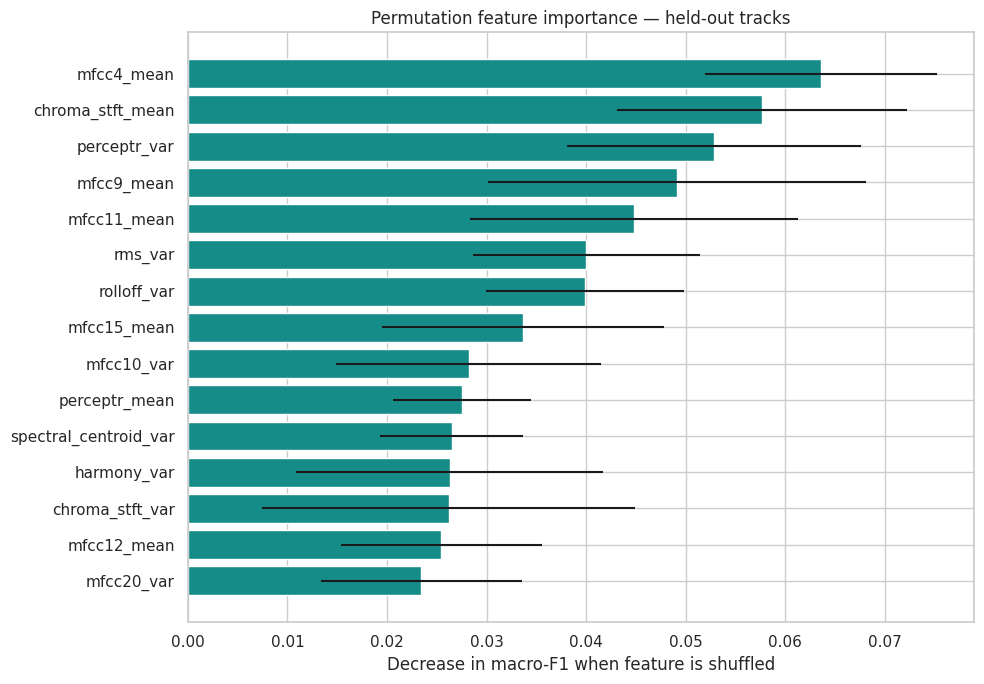

Saved chart and table in: /content/outputs/part2_2


In [ ]:
# PART 2.2 — Which audio features matter most?
#This part estimates how much each audio feature contributes to the selected model’s predictions. It helps identify which measured audio characteristics may be useful for distinguishing genres.
# Run after Part 2 in the same Colab runtime.

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

MODEL_PATH = Path("/content/outputs/part2/30_sec_best_model.joblib")
OUTPUT_DIR = Path("/content/outputs/part2_2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError("Run Part 2 first; the saved 30-second model was not found.")

model_bundle = joblib.load(MODEL_PATH)
model = model_bundle["model"]
feature_names = list(model_bundle["features"])

# Recreate Part 2's held-out track split.
tracks = data_30[["track_id", "label"]].drop_duplicates("track_id")
_, test_tracks = train_test_split(
    tracks,
    test_size=0.20,
    random_state=SEED,
    stratify=tracks["label"],
)
test_ids = set(test_tracks["track_id"].astype(str))

test_rows = data_30[
    data_30["track_id"].astype(str).isin(test_ids)
].copy()

X_test = test_rows[feature_names].replace([np.inf, -np.inf], np.nan)
y_test = test_rows["label"].astype(str)

# Measure the drop in macro-F1 when each feature is shuffled.
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1,
)

importance_table = pd.DataFrame({
    "feature": feature_names,
    "mean_macro_f1_drop": importance.importances_mean,
    "std_macro_f1_drop": importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

importance_table.to_csv(
    OUTPUT_DIR / "permutation_feature_importance.csv",
    index=False,
)

print("Most influential features for the saved 30-second model:")
display(importance_table.head(15))

# Plot the top 15 features.
top = importance_table.head(15).sort_values("mean_macro_f1_drop")

plt.figure(figsize=(10, 7))
plt.barh(
    top["feature"],
    top["mean_macro_f1_drop"],
    xerr=top["std_macro_f1_drop"],
    color="#168c88",
)
plt.xlabel("Decrease in macro-F1 when feature is shuffled")
plt.title("Permutation feature importance — held-out tracks")
plt.tight_layout()

chart_path = OUTPUT_DIR / "permutation_feature_importance.png"
plt.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved chart and table in: {OUTPUT_DIR}")

Majority-class baseline:


,dataset,model,accuracy,macro_f1,weighted_f1,held_out_tracks
0,30_sec,Majority-class baseline,0.1,0.018182,0.018182,200
1,3_sec,Majority-class baseline,0.1,0.018182,0.018182,200


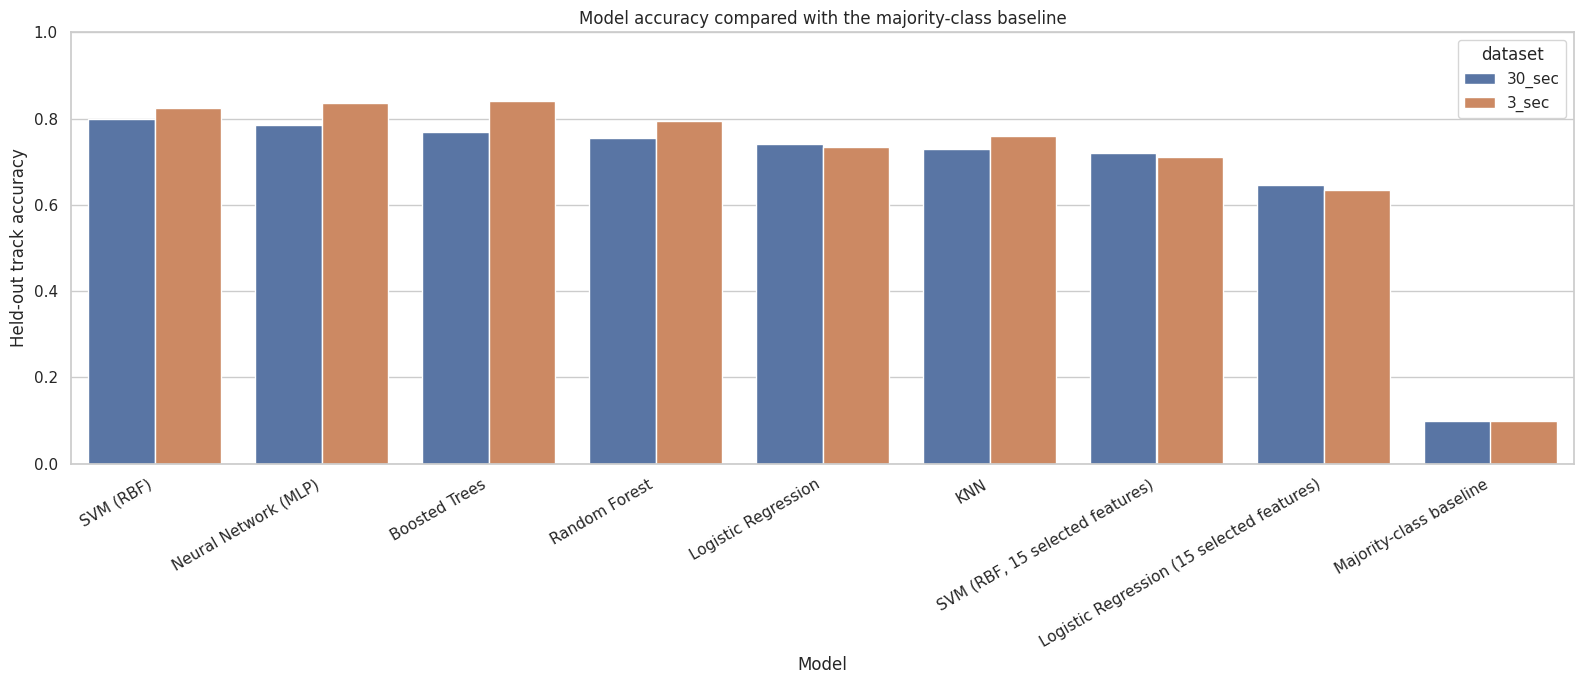

Saved baseline comparison in: /content/outputs/part2_3


In [ ]:
# Part 2.3 — Compare the models with a simple majority-class baseline.
#This part compares the trained models with a simple baseline that always predicts the most common genre. It checks whether the models learn useful patterns beyond that basic strategy.
# Run after Part 2.1 in the same Colab runtime.

from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

BASELINE_DIR = Path("/content/outputs/part2_3")
BASELINE_DIR.mkdir(parents=True, exist_ok=True)

baseline_rows = []

for data, duration in [(data_30, "30_sec"), (data_3, "3_sec")]:
    # Count each original song once, even in the 3-second dataset.
    train_tracks = (
        data[data["track_id"].astype(str).isin(trainval_ids)]
        [["track_id", "label"]]
        .drop_duplicates("track_id")
    )
    majority_genre = (
        train_tracks["label"].value_counts().sort_index().idxmax()
    )

    test_tracks = (
        data[data["track_id"].astype(str).isin(test_ids)]
        [["track_id", "label"]]
        .drop_duplicates("track_id")
    )
    y_true = test_tracks["label"].astype(str).tolist()
    y_pred = [majority_genre] * len(y_true)

    baseline_rows.append({
        "dataset": duration,
        "model": "Majority-class baseline",
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true, y_pred,
            labels=genre_labels,
            average="weighted",
            zero_division=0,
        ),
        "held_out_tracks": len(y_true),
    })

baseline = pd.DataFrame(baseline_rows)
baseline.to_csv(BASELINE_DIR / "majority_baseline_metrics.csv", index=False)

# Combine the baseline with the Part 2.1 model comparison.
combined_results = pd.concat(
    [results_21, baseline],
    ignore_index=True,
)
combined_results.to_csv(
    BASELINE_DIR / "models_vs_baseline.csv",
    index=False,
)

print("Majority-class baseline:")
display(baseline)

# Chart comparing every model with the baseline.
plt.figure(figsize=(16, 7))
sns.barplot(
    data=combined_results,
    x="model",
    y="accuracy",
    hue="dataset",
)
plt.title("Model accuracy compared with the majority-class baseline")
plt.xlabel("Model")
plt.ylabel("Held-out track accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    BASELINE_DIR / "models_vs_baseline_accuracy.png",
    dpi=180,
)
plt.show()
plt.close()

print(f"Saved baseline comparison in: {BASELINE_DIR}")

,fraction,training_tracks,train_f1_mean,train_f1_std,validation_f1_mean,validation_f1_std
0,0.10,64,1.000000,0.0,0.494201,0.044525
1,0.25,160,1.000000,0.0,0.606983,0.005071
2,0.50,320,1.000000,0.0,0.639726,0.005639
3,0.75,480,0.997916,0.0,0.658654,0.012799
4,1.00,640,0.998437,0.0,0.720385,0.000000


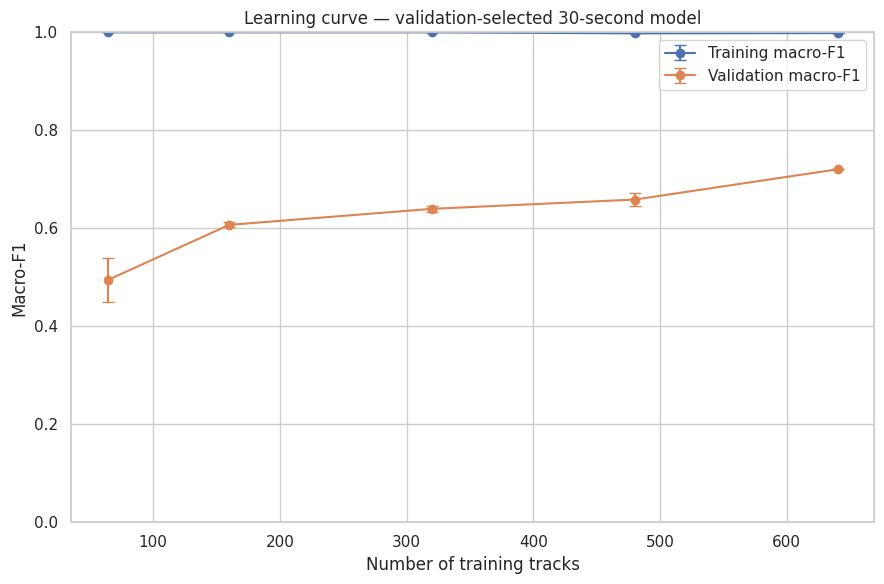

Most frequent directed confusion: disco predicted as hiphop (5 held-out track(s)).


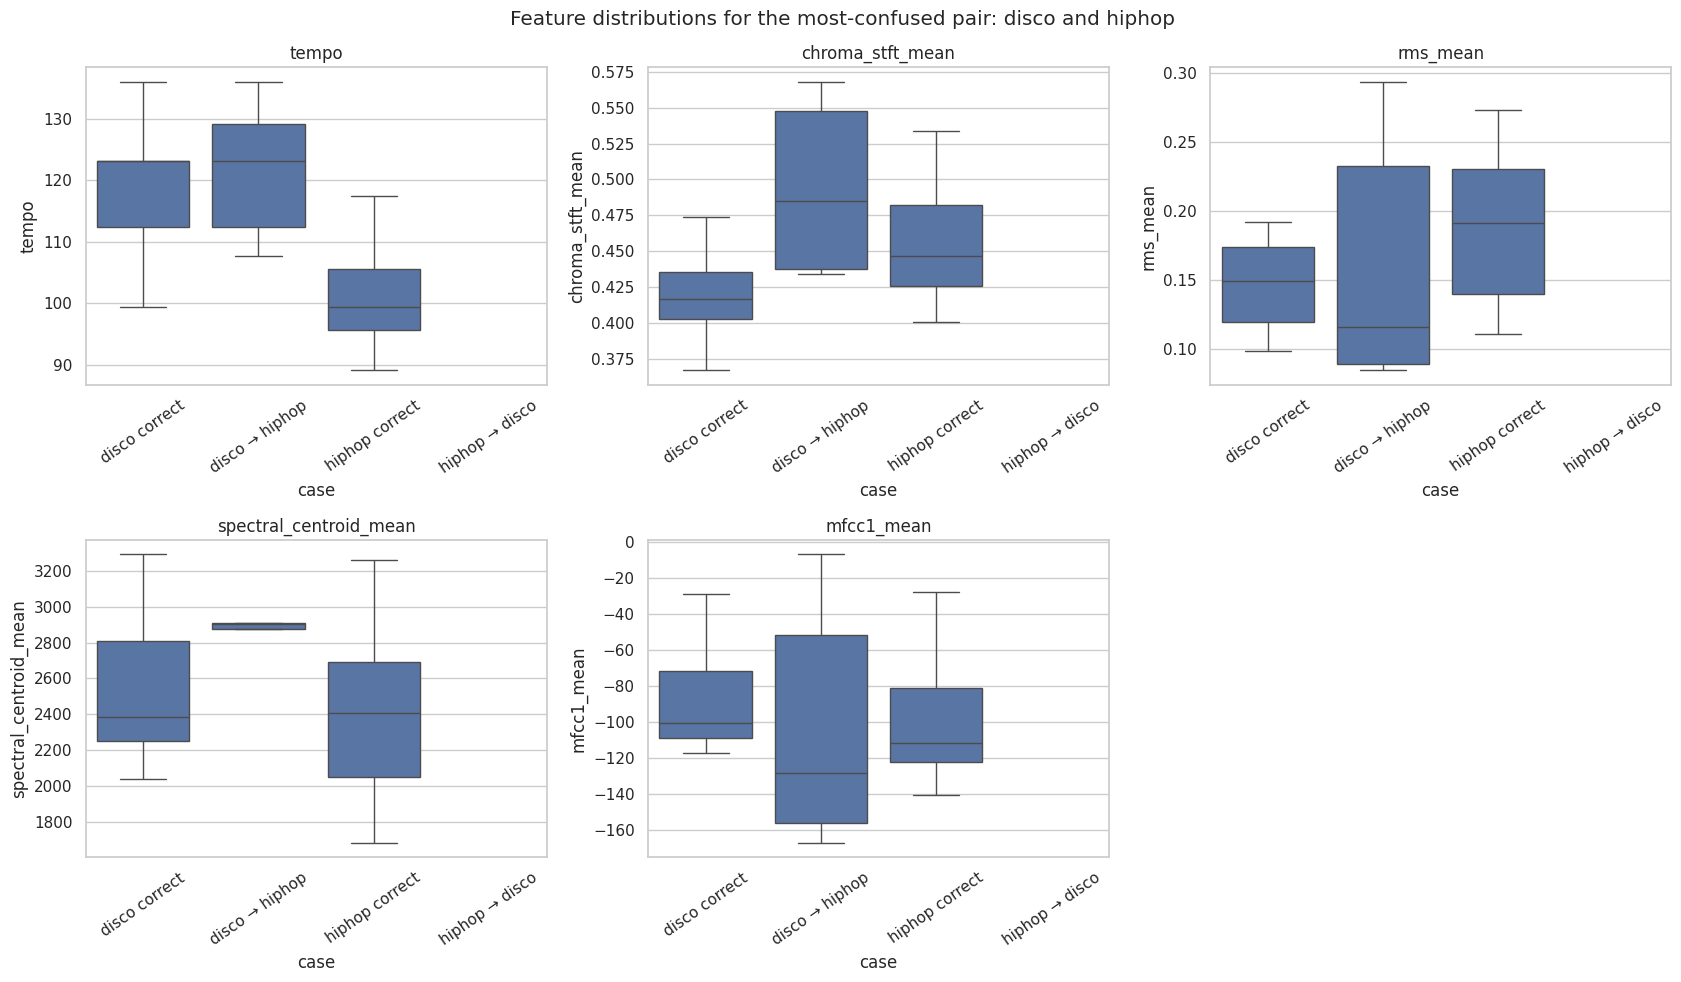

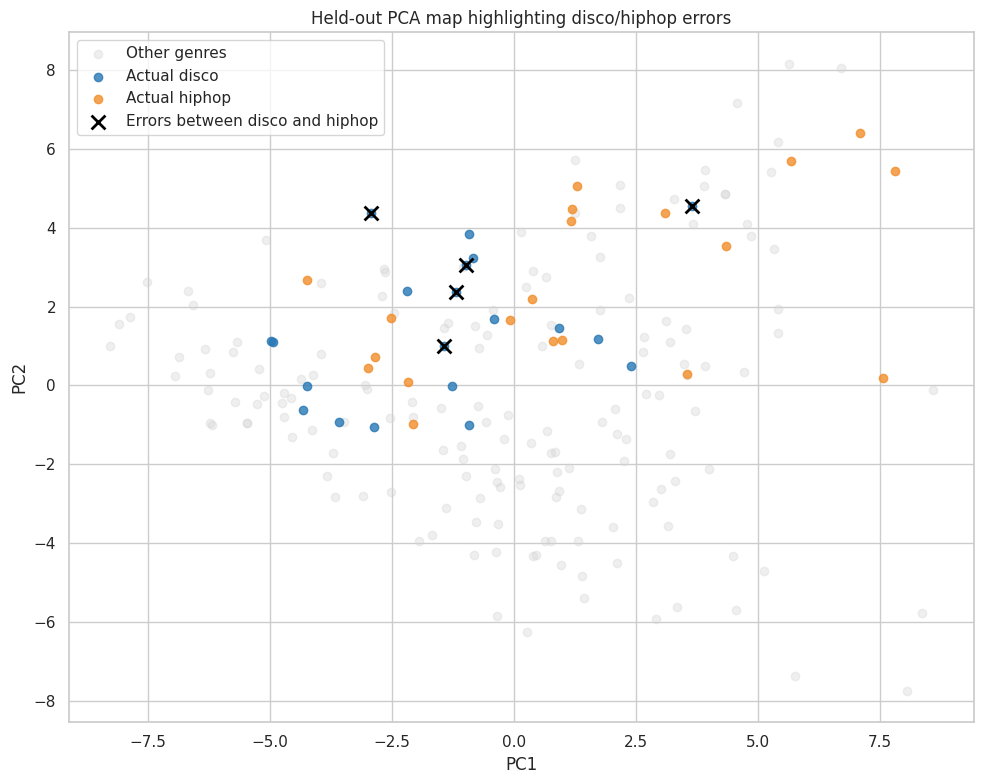


Part 2.4 outputs saved in: /content/outputs/part2_4


In [ ]:
# PART 2.4 — Learning curve and confused-genre analysis
#This part examines model performance as the amount of training data increases and investigates commonly confused genres. It helps show whether more training data may help and where the model’s mistakes occur.
# Run after Parts 2 and 2.1 in the same Colab runtime.

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PART24_DIR = Path("/content/outputs/part2_4")
PART24_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = Path("/content/outputs/part2/30_sec_best_model.joblib")
if not MODEL_PATH.exists():
    raise FileNotFoundError("Run Part 2 first; its 30-second model was not found.")

model_bundle = joblib.load(MODEL_PATH)
best_model = model_bundle["model"]
feature_names = list(model_bundle["features"])

# The notebook should still have these variables from Part 2.
if "data_30" not in globals() or "train_ids" not in globals() or "validation_ids" not in globals():
    raise NameError("Run Part 2 first in this Colab runtime so its data and track splits are available.")

# -------------------------------
# A. Learning curve
# -------------------------------
# Train on progressively larger, genre-stratified subsets of the training tracks.
# Score on the same validation tracks each time.

train_meta = (
    data_30[data_30["track_id"].astype(str).isin(train_ids)]
    [["track_id", "label"]]
    .drop_duplicates("track_id")
)

validation_rows = data_30[
    data_30["track_id"].astype(str).isin(validation_ids)
].copy()

X_validation = validation_rows[feature_names].replace([np.inf, -np.inf], np.nan)
y_validation = validation_rows["label"].astype(str)

fractions = [0.10, 0.25, 0.50, 0.75, 1.00]
repeats = 3
learning_rows = []

for fraction in fractions:
    for repeat in range(repeats):
        if fraction == 1.0:
            subset_meta = train_meta.copy()
        else:
            subset_meta, _ = train_test_split(
                train_meta,
                train_size=fraction,
                random_state=SEED + repeat + int(fraction * 100),
                stratify=train_meta["label"],
            )

        subset_ids = set(subset_meta["track_id"].astype(str))
        subset_rows = data_30[
            data_30["track_id"].astype(str).isin(subset_ids)
        ].copy()

        X_subset = subset_rows[feature_names].replace(
            [np.inf, -np.inf], np.nan
        )
        y_subset = subset_rows["label"].astype(str)

        learning_model = clone(best_model)
        learning_model.fit(X_subset, y_subset)

        train_predictions = learning_model.predict(X_subset)
        validation_predictions = learning_model.predict(X_validation)

        learning_rows.append({
            "fraction": fraction,
            "training_tracks": len(subset_meta),
            "repeat": repeat + 1,
            "train_macro_f1": f1_score(
                y_subset, train_predictions,
                labels=genre_labels,
                average="macro",
                zero_division=0,
            ),
            "validation_macro_f1": f1_score(
                y_validation, validation_predictions,
                labels=genre_labels,
                average="macro",
                zero_division=0,
            ),
        })

learning_results = pd.DataFrame(learning_rows)
learning_results.to_csv(
    PART24_DIR / "learning_curve_results.csv",
    index=False,
)

learning_summary = (
    learning_results.groupby(["fraction", "training_tracks"])
    .agg(
        train_f1_mean=("train_macro_f1", "mean"),
        train_f1_std=("train_macro_f1", "std"),
        validation_f1_mean=("validation_macro_f1", "mean"),
        validation_f1_std=("validation_macro_f1", "std"),
    )
    .reset_index()
    .fillna(0)
)

display(learning_summary)

plt.figure(figsize=(9, 6))
plt.errorbar(
    learning_summary["training_tracks"],
    learning_summary["train_f1_mean"],
    yerr=learning_summary["train_f1_std"],
    marker="o",
    capsize=4,
    label="Training macro-F1",
)
plt.errorbar(
    learning_summary["training_tracks"],
    learning_summary["validation_f1_mean"],
    yerr=learning_summary["validation_f1_std"],
    marker="o",
    capsize=4,
    label="Validation macro-F1",
)
plt.xlabel("Number of training tracks")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.title("Learning curve — validation-selected 30-second model")
plt.legend()
plt.tight_layout()
plt.savefig(
    PART24_DIR / "learning_curve.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()
plt.close()

# -------------------------------
# B. Investigate the most-confused genre pair
# -------------------------------
# This uses the untouched held-out tracks for diagnosis after model selection.

if "test_ids" not in globals():
    raise NameError("Part 2's test_ids are missing. Run Part 2 again first.")

test_rows = data_30[
    data_30["track_id"].astype(str).isin(test_ids)
].copy()

X_test = test_rows[feature_names].replace([np.inf, -np.inf], np.nan)
actual = test_rows["label"].astype(str).to_numpy()
predicted = best_model.predict(X_test)

matrix = confusion_matrix(actual, predicted, labels=genre_labels)
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)

if off_diagonal.max() == 0:
    print("There are no misclassified test tracks to investigate.")
else:
    actual_index, predicted_index = np.unravel_index(
        np.argmax(off_diagonal), off_diagonal.shape
    )
    genre_a = genre_labels[actual_index]
    genre_b = genre_labels[predicted_index]
    error_count = int(off_diagonal[actual_index, predicted_index])

    print(
        f"Most frequent directed confusion: {genre_a} predicted as {genre_b} "
        f"({error_count} held-out track(s))."
    )

    pair_data = test_rows.copy()
    pair_data["actual_genre"] = actual
    pair_data["predicted_genre"] = predicted

    cases = [
        (pair_data["actual_genre"] == genre_a) &
        (pair_data["predicted_genre"] == genre_a),
        (pair_data["actual_genre"] == genre_a) &
        (pair_data["predicted_genre"] == genre_b),
        (pair_data["actual_genre"] == genre_b) &
        (pair_data["predicted_genre"] == genre_b),
        (pair_data["actual_genre"] == genre_b) &
        (pair_data["predicted_genre"] == genre_a),
    ]
    case_names = [
        f"{genre_a} correct",
        f"{genre_a} → {genre_b}",
        f"{genre_b} correct",
        f"{genre_b} → {genre_a}",
    ]

    pair_data["case"] = np.select(cases, case_names, default="Other")
    pair_data = pair_data[pair_data["case"] != "Other"].copy()

    pair_data.groupby("case")[
        [c for c in [
            "tempo",
            "chroma_stft_mean",
            "rms_mean",
            "spectral_centroid_mean",
            "mfcc1_mean",
        ] if c in pair_data.columns]
    ].mean().to_csv(PART24_DIR / "confused_pair_feature_means.csv")

    plot_features = [
        c for c in [
            "tempo",
            "chroma_stft_mean",
            "rms_mean",
            "spectral_centroid_mean",
            "mfcc1_mean",
        ]
        if c in pair_data.columns
    ]

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    axes = axes.flatten()

    for ax, feature in zip(axes, plot_features):
        sns.boxplot(
            data=pair_data,
            x="case",
            y=feature,
            order=case_names,
            ax=ax,
            showfliers=False,
        )
        ax.set_title(f"{feature}")
        ax.tick_params(axis="x", rotation=35)

    for ax in axes[len(plot_features):]:
        ax.axis("off")

    fig.suptitle(
        f"Feature distributions for the most-confused pair: {genre_a} and {genre_b}"
    )
    fig.tight_layout()
    fig.savefig(
        PART24_DIR / "confused_pair_feature_distributions.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # PCA map: fit scaling and PCA on training tracks, then project test tracks.
    train_rows = data_30[
        data_30["track_id"].astype(str).isin(train_ids)
    ].copy()
    X_train = train_rows[feature_names].replace([np.inf, -np.inf], np.nan)

    map_scaler = StandardScaler()
    X_train_scaled = map_scaler.fit_transform(X_train)
    X_test_scaled = map_scaler.transform(X_test)

    map_pca = PCA(n_components=2, random_state=SEED)
    map_pca.fit(X_train_scaled)
    test_coordinates = map_pca.transform(X_test_scaled)

    map_data = pd.DataFrame({
        "PC1": test_coordinates[:, 0],
        "PC2": test_coordinates[:, 1],
        "actual_genre": actual,
        "predicted_genre": predicted,
    })

    pair_error = (
        ((map_data["actual_genre"] == genre_a) &
         (map_data["predicted_genre"] == genre_b)) |
        ((map_data["actual_genre"] == genre_b) &
         (map_data["predicted_genre"] == genre_a))
    )

    plt.figure(figsize=(10, 8))
    plt.scatter(
        map_data.loc[~map_data["actual_genre"].isin([genre_a, genre_b]), "PC1"],
        map_data.loc[~map_data["actual_genre"].isin([genre_a, genre_b]), "PC2"],
        color="lightgray",
        alpha=0.35,
        label="Other genres",
    )

    for genre, color in [(genre_a, "#2878B5"), (genre_b, "#F28E2B")]:
        mask = map_data["actual_genre"] == genre
        plt.scatter(
            map_data.loc[mask, "PC1"],
            map_data.loc[mask, "PC2"],
            color=color,
            alpha=0.8,
            label=f"Actual {genre}",
        )

    plt.scatter(
        map_data.loc[pair_error, "PC1"],
        map_data.loc[pair_error, "PC2"],
        marker="x",
        s=100,
        linewidths=2,
        color="black",
        label=f"Errors between {genre_a} and {genre_b}",
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"Held-out PCA map highlighting {genre_a}/{genre_b} errors")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        PART24_DIR / "confused_pair_pca_map.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

print(f"\nPart 2.4 outputs saved in: {PART24_DIR}")

In [ ]:
!pip -q install kagglehub

import kagglehub
from pathlib import Path

audio_root = Path(
    kagglehub.dataset_download(
        "andradaolteanu/gtzan-dataset-music-genre-classification"
    )
)

print("Dataset downloaded to:", audio_root)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Dataset downloaded to: /kaggle/input/gtzan-dataset-music-genre-classification


In [ ]:
# 2.5A — Find original WAV tracks and match them to the Part 2 splits
# Run Part 2 and the KaggleHub download cell first.

import re
import zipfile
from pathlib import Path, PurePosixPath

required_split_vars = ["train_ids", "validation_ids", "test_ids", "genre_labels"]
missing_split_vars = [name for name in required_split_vars if name not in globals()]
if missing_split_vars:
    raise RuntimeError(
        "Run Part 2 first in this Colab runtime. Missing: "
        + ", ".join(missing_split_vars)
    )

# KaggleHub's download cell should have created this variable.
if "audio_root" not in globals():
    raise RuntimeError("Run the KaggleHub download cell first.")

downloaded_root = Path(audio_root)
if not downloaded_root.exists():
    raise FileNotFoundError(f"Downloaded dataset folder not found: {downloaded_root}")

GENRES_CNN = {
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock"
}
genre_pattern = "|".join(sorted(GENRES_CNN, key=len, reverse=True))
track_pattern = re.compile(rf"^({genre_pattern})[._-](\d+)", re.IGNORECASE)

# Some Kaggle copies store the WAV folders inside ZIP files.
# Extract only WAV files into Colab's temporary storage.
extracted_root = Path("/content/cnn_audio/kagglehub_wavs")
extracted_root.mkdir(parents=True, exist_ok=True)

wav_count = 0
for archive_path in downloaded_root.rglob("*.zip"):
    try:
        with zipfile.ZipFile(archive_path) as archive:
            for member in archive.infolist():
                if member.is_dir() or not member.filename.lower().endswith(".wav"):
                    continue

                relative = PurePosixPath(member.filename)
                if relative.is_absolute() or ".." in relative.parts:
                    continue

                destination = extracted_root.joinpath(*relative.parts)
                destination.parent.mkdir(parents=True, exist_ok=True)

                # Avoid extracting the same path more than once.
                if not destination.exists():
                    destination.write_bytes(archive.read(member))
                    wav_count += 1
    except zipfile.BadZipFile:
        print(f"Skipping non-readable ZIP: {archive_path.name}")

print(f"WAV files extracted from ZIPs: {wav_count}")

# Search both the downloaded folder and the extracted WAV folder.
audio_search_roots = [downloaded_root, extracted_root]
audio_map = {}
audio_labels = {}

for search_root in audio_search_roots:
    for path in search_root.rglob("*.wav"):
        stem = path.stem.lower().replace(" ", "")
        match = track_pattern.match(stem)

        if match:
            genre = match.group(1).lower()
            track_id = f"{genre}.{int(match.group(2)):05d}"
        else:
            folder_genre = path.parent.name.lower().replace(" ", "")
            if folder_genre not in GENRES_CNN:
                continue
            genre = folder_genre
            track_id = f"{genre}.{stem}"

        # Keep the first copy found for each track.
        if track_id not in audio_map:
            audio_map[track_id] = path
            audio_labels[track_id] = genre

if not audio_map:
    top_level_items = [item.name for item in downloaded_root.iterdir()][:20]
    raise ValueError(
        "No labelled WAV files were found in the KaggleHub download or its ZIPs. "
        f"Files/folders at the download location include: {top_level_items}"
    )

split_ids_cnn = {
    "train": set(map(str, train_ids)),
    "validation": set(map(str, validation_ids)),
    "test": set(map(str, test_ids)),
}

expected_ids_cnn = set().union(*split_ids_cnn.values())
available_split_ids = expected_ids_cnn & set(audio_map)
missing_audio_ids = expected_ids_cnn - set(audio_map)

print(f"Recognized {len(audio_map)} unique labelled WAV tracks.")
print(
    f"Tracks matched to Part 2 splits: "
    f"{len(available_split_ids)} / {len(expected_ids_cnn)}"
)

if missing_audio_ids:
    print("Some feature-table tracks have no matching WAV and will be excluded.")
    print("Examples:", sorted(missing_audio_ids)[:8])

for split_name, ids in split_ids_cnn.items():
    present = ids & set(audio_map)
    present_genres = {audio_labels[track_id] for track_id in present}
    absent_genres = GENRES_CNN - present_genres

    print(
        f"{split_name.title()}: {len(present)} WAV tracks; "
        f"genres present={len(present_genres)}/10"
    )

    if not present or absent_genres:
        raise ValueError(
            f"The {split_name} split is missing genre coverage: "
            f"{sorted(absent_genres)}. Check that the full GTZAN WAV dataset "
            "was downloaded."
        )

WAV files extracted from ZIPs: 0
Recognized 1000 unique labelled WAV tracks.
Tracks matched to Part 2 splits: 1000 / 1000
Train: 640 WAV tracks; genres present=10/10
Validation: 160 WAV tracks; genres present=10/10
Test: 200 WAV tracks; genres present=10/10


In [ ]:
# Check that WAV-folder genres match the feature-table genre labels

label_col = next(
    (col for col in ["label", "genre", "class"] if col in data_3.columns),
    None
)
if label_col is None:
    raise ValueError(f"Can't find a genre column. Columns are: {list(data_3.columns)}")

def normalize_genre(value):
    return str(value).strip().lower().replace("-", "").replace("_", "").replace(" ", "")

feature_labels = (
    data_3[["track_id", label_col]]
    .drop_duplicates("track_id")
    .assign(
        track_id=lambda d: d["track_id"].astype(str),
        feature_genre=lambda d: d[label_col].map(normalize_genre)
    )
    .set_index("track_id")["feature_genre"]
)

common_ids = sorted(set(feature_labels.index) & set(audio_labels))
mismatches = [
    (track_id, feature_labels[track_id], normalize_genre(audio_labels[track_id]))
    for track_id in common_ids
    if feature_labels[track_id] != normalize_genre(audio_labels[track_id])
]

print(f"Tracks compared: {len(common_ids)}")
print(f"Genre-label mismatches: {len(mismatches)}")
print("Examples:", mismatches[:10])

print("\nCNN training crop counts:")
print(pd.Series(crop_labels_cnn[train_mask_cnn]).value_counts().sort_index())

print("\nCNN validation crop counts:")
print(pd.Series(crop_labels_cnn[validation_mask_cnn]).value_counts().sort_index())

Tracks compared: 1000
Genre-label mismatches: 0
Examples: []

CNN training crop counts:
blues        192
classical    192
country      192
disco        192
hiphop       192
jazz         192
metal        192
pop          192
reggae       192
rock         192
Name: count, dtype: int64

CNN validation crop counts:
blues        48
classical    48
country      48
disco        48
hiphop       48
jazz         48
metal        48
pop          48
reggae       48
rock         48
Name: count, dtype: int64


Making 6-sec Mel crops:   0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_1539/1767732826.py:54: UserWarning: PySoundFile failed. Trying audioread instead.
  signal, _ = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Skipped unreadable track jazz.00054: 
Cached new 6-second spectrograms at: /content/outputs/individual_cnn/mel_cache_6sec_5crops_v1.npz
Spectrogram array: (4995, 64, 188, 1)
999 songs × up to 5 excerpts per song


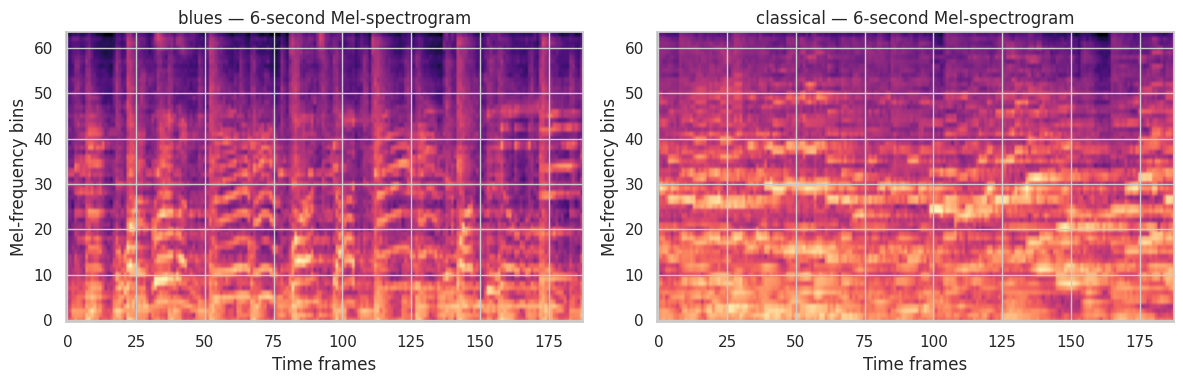

In [ ]:
# 2.5B — Build and cache five 6-second Mel-spectrogram excerpts per song
# while keeping memory and training time manageable.

from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tqdm.auto import tqdm

# Audio and spectrogram settings
SEED_CNN = 409
SR_CNN = 16000
CLIP_SECONDS_CNN = 6
CLIP_SAMPLES_CNN = SR_CNN * CLIP_SECONDS_CNN

N_MELS_CNN = 64
N_FFT_CNN = 1024
HOP_CNN = 512
TARGET_FRAMES_CNN = 188
CROPS_PER_TRACK_CNN = 5

# Use a new cache file for the 6-second crops.
cnn_output_dir = Path("/content/outputs/individual_cnn")
cnn_output_dir.mkdir(parents=True, exist_ok=True)
cache_path_cnn = cnn_output_dir / "mel_cache_6sec_5crops_v1.npz"

if not available_split_ids:
    raise ValueError("No audio tracks match the Part 2 train/validation/test splits.")

if cache_path_cnn.exists():
    cached = np.load(cache_path_cnn, allow_pickle=False)
    X_cnn = cached["X"].astype(np.float32)
    crop_track_ids_cnn = cached["track_ids"].astype(str)
    crop_labels_cnn = cached["labels"].astype(str)
    print(f"Loaded cached 6-second spectrograms: {X_cnn.shape}")

else:
    spec_rows = []
    crop_track_rows = []
    crop_label_rows = []

    split_track_subset = sorted(available_split_ids)

    for track_id in tqdm(split_track_subset, desc="Making 6-sec Mel crops"):
        audio_path = audio_map[track_id]
        genre = audio_labels[track_id]

        try:
            signal, _ = librosa.load(
                audio_path,
                sr=SR_CNN,
                mono=True
            )

            if signal.size == 0:
                raise ValueError("Audio file is empty.")

            # Pad unusually short tracks so each excerpt is six seconds.
            if signal.size < CLIP_SAMPLES_CNN:
                signal = np.pad(
                    signal,
                    (0, CLIP_SAMPLES_CNN - signal.size)
                )

            # Spread five excerpts across the length of each original song.
            max_start = max(0, signal.size - CLIP_SAMPLES_CNN)
            starts = np.linspace(
                0,
                max_start,
                CROPS_PER_TRACK_CNN,
                dtype=int
            )

            for start in starts:
                clip = signal[start:start + CLIP_SAMPLES_CNN]

                mel_power = librosa.feature.melspectrogram(
                    y=clip,
                    sr=SR_CNN,
                    n_fft=N_FFT_CNN,
                    hop_length=HOP_CNN,
                    n_mels=N_MELS_CNN,
                    power=2.0
                )

                mel_db = librosa.power_to_db(mel_power, ref=np.max)
                mel_db = (np.clip(mel_db, -80, 0) + 80) / 80.0

                # Pad or crop so every spectrogram has the same dimensions.
                if mel_db.shape[1] < TARGET_FRAMES_CNN:
                    mel_db = np.pad(
                        mel_db,
                        (
                            (0, 0),
                            (0, TARGET_FRAMES_CNN - mel_db.shape[1])
                        )
                    )

                mel_db = mel_db[:, :TARGET_FRAMES_CNN]

                spec_rows.append(
                    mel_db[..., np.newaxis].astype(np.float32)
                )
                crop_track_rows.append(track_id)
                crop_label_rows.append(genre)

        except Exception as exc:
            print(f"Skipped unreadable track {track_id}: {exc}")

    if not spec_rows:
        raise ValueError(
            "No spectrograms were created. Check that the WAV files are readable."
        )

    X_cnn = np.stack(spec_rows)
    crop_track_ids_cnn = np.asarray(crop_track_rows, dtype=str)
    crop_labels_cnn = np.asarray(crop_label_rows, dtype=str)

    np.savez_compressed(
        cache_path_cnn,
        X=X_cnn,
        track_ids=crop_track_ids_cnn,
        labels=crop_labels_cnn
    )

    print(f"Cached new 6-second spectrograms at: {cache_path_cnn}")

print("Spectrogram array:", X_cnn.shape)
print(
    f"{len(set(crop_track_ids_cnn))} songs × "
    f"up to {CROPS_PER_TRACK_CNN} excerpts per song"
)

# Visual check: display one actual excerpt from two genres.
example_genres = sorted(set(crop_labels_cnn))[:2]

fig, axes = plt.subplots(
    1,
    len(example_genres),
    figsize=(12, 4)
)

if len(example_genres) == 1:
    axes = [axes]

for ax, genre in zip(axes, example_genres):
    example_index = int(np.flatnonzero(crop_labels_cnn == genre)[0])

    ax.imshow(
        X_cnn[example_index, :, :, 0],
        origin="lower",
        aspect="auto",
        cmap="magma"
    )
    ax.set_title(f"{genre} — 6-second Mel-spectrogram")
    ax.set_xlabel("Time frames")
    ax.set_ylabel("Mel-frequency bins")

plt.tight_layout()
plt.show()

In [ ]:
# 2.5C — Train a regularized CNN on six-second Mel-spectrograms
# Validation selects the checkpoint; test tracks are used only for final scoring.

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

if X_cnn.shape[1:] != (N_MELS_CNN, TARGET_FRAMES_CNN, 1):
    raise ValueError(
        f"Expected inputs shaped ({N_MELS_CNN}, {TARGET_FRAMES_CNN}, 1), "
        f"but got {X_cnn.shape[1:]}. Run the updated 2.5B cell first."
    )

tf.keras.utils.set_random_seed(SEED_CNN)

# Encode all genres consistently.
genre_encoder_cnn = LabelEncoder().fit(sorted(GENRES_CNN))
y_cnn = genre_encoder_cnn.transform(crop_labels_cnn)

# Match each crop to the original track's Part 2 split.
train_ids_cnn = set(map(str, train_ids)) & set(audio_map)
validation_ids_cnn = set(map(str, validation_ids)) & set(audio_map)
test_ids_cnn = set(map(str, test_ids)) & set(audio_map)

train_mask_cnn = np.isin(crop_track_ids_cnn, list(train_ids_cnn))
validation_mask_cnn = np.isin(crop_track_ids_cnn, list(validation_ids_cnn))
test_mask_cnn = np.isin(crop_track_ids_cnn, list(test_ids_cnn))

X_train_cnn, y_train_cnn = X_cnn[train_mask_cnn], y_cnn[train_mask_cnn]
X_val_cnn, y_val_cnn = X_cnn[validation_mask_cnn], y_cnn[validation_mask_cnn]
X_test_cnn = X_cnn[test_mask_cnn]

train_crop_ids_cnn = crop_track_ids_cnn[train_mask_cnn]
val_crop_ids_cnn = crop_track_ids_cnn[validation_mask_cnn]
test_crop_ids_cnn = crop_track_ids_cnn[test_mask_cnn]

# Confirm no original song appears in more than one split.
assert not (set(train_crop_ids_cnn) & set(val_crop_ids_cnn))
assert not (set(train_crop_ids_cnn) & set(test_crop_ids_cnn))
assert not (set(val_crop_ids_cnn) & set(test_crop_ids_cnn))

print(
    "Six-second crop split shapes:",
    X_train_cnn.shape,
    X_val_cnn.shape,
    X_test_cnn.shape
)

# Light spectrogram augmentation and regularization.
l2_cnn = tf.keras.regularizers.l2(1e-4)

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(N_MELS_CNN, TARGET_FRAMES_CNN, 1)),

    tf.keras.layers.RandomTranslation(
        height_factor=0.02,
        width_factor=0.04,
        fill_mode="nearest",
        seed=SEED_CNN,
        name="spectrogram_shift"
    ),
    tf.keras.layers.GaussianNoise(0.01, name="spectrogram_noise"),

    tf.keras.layers.Conv2D(
        24, 3, padding="same", activation="relu",
        kernel_regularizer=l2_cnn, name="conv1"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(
        48, 3, padding="same", activation="relu",
        kernel_regularizer=l2_cnn, name="conv2"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(
        96, 3, padding="same", activation="relu",
        kernel_regularizer=l2_cnn, name="conv3"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.45),
    tf.keras.layers.Dense(
        len(genre_encoder_cnn.classes_),
        activation="softmax",
        name="genre_probabilities"
    ),
], name="mel_spectrogram_cnn")

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Balance genre contributions using training labels only.
class_ids = np.unique(y_train_cnn)
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train_cnn
)
class_weights_cnn = dict(zip(class_ids.tolist(), weights.tolist()))

# Select and stop using validation accuracy, not validation loss.
early_stop_cnn = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=8,
    restore_best_weights=True
)
reduce_lr_cnn = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_accuracy",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("TensorFlow sees GPU:", bool(tf.config.list_physical_devices("GPU")))

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=40,
    batch_size=64,
    class_weight=class_weights_cnn,
    callbacks=[early_stop_cnn, reduce_lr_cnn],
    verbose=1,
)

# Average crop probabilities so each held-out song gets one prediction.
crop_prob_cnn = cnn_model.predict(
    X_test_cnn,
    batch_size=64,
    verbose=0
)

prob_frame_cnn = pd.DataFrame(
    crop_prob_cnn,
    columns=genre_encoder_cnn.classes_
)
prob_frame_cnn["track_id"] = test_crop_ids_cnn

track_prob_cnn = prob_frame_cnn.groupby("track_id")[
    list(genre_encoder_cnn.classes_)
].mean()

true_label_by_track_cnn = {
    track_id: audio_labels[track_id]
    for track_id in track_prob_cnn.index
}
cnn_test_ids_sorted = sorted(track_prob_cnn.index)

y_true_cnn = [
    true_label_by_track_cnn[track_id]
    for track_id in cnn_test_ids_sorted
]
y_pred_cnn = (
    track_prob_cnn.loc[cnn_test_ids_sorted]
    .idxmax(axis=1)
    .tolist()
)

cnn_accuracy = accuracy_score(y_true_cnn, y_pred_cnn)
cnn_macro_f1 = f1_score(
    y_true_cnn,
    y_pred_cnn,
    labels=genre_encoder_cnn.classes_,
    average="macro",
    zero_division=0
)

print(f"\nCNN test track accuracy: {cnn_accuracy:.3f}")
print(f"CNN test track macro-F1: {cnn_macro_f1:.3f}")
print(classification_report(
    y_true_cnn,
    y_pred_cnn,
    labels=genre_encoder_cnn.classes_,
    zero_division=0
))

Six-second crop split shapes: (3200, 64, 188, 1) (800, 64, 188, 1) (995, 64, 188, 1)
TensorFlow sees GPU: False
Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.2806 - loss: 1.9762 - val_accuracy: 0.1000 - val_loss: 2.3261 - learning_rate: 3.0000e-04
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 120s 2s/step - accuracy: 0.3800 - loss: 1.7138 - val_accuracy: 0.1000 - val_loss: 2.4663 - learning_rate: 3.0000e-04
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.4244 - loss: 1.6310 - val_accuracy: 0.1000 - val_loss: 2.7082 - learning_rate: 3.0000e-04
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4393 - loss: 1.5959
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
50/50 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.4481 - loss: 1.5818 - val_accuracy: 0.1000 - val_loss: 3.0397 - learning_rate: 3.0000e-04
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 151s 3s/step - accuracy: 0.4769 - loss: 1.5216 - val_accuracy: 0.1000 - val_loss: 

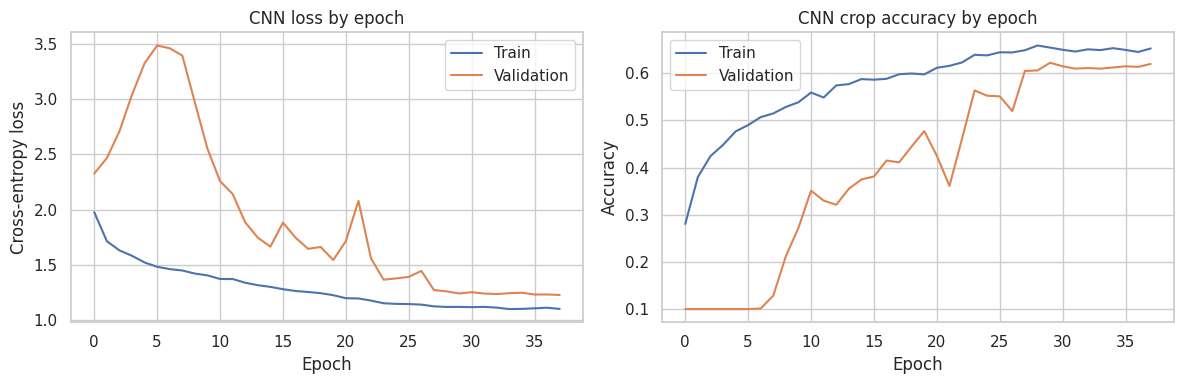

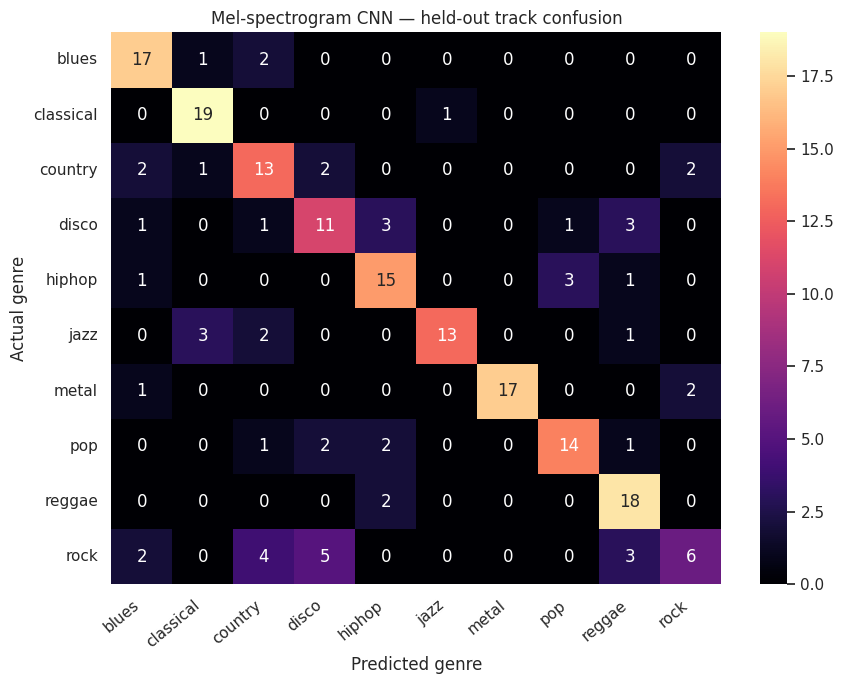

Most frequent CNN errors (actual -> predicted):
rock -> disco: 5 tracks
rock -> country: 4 tracks
rock -> reggae: 3 tracks
jazz -> classical: 3 tracks
hiphop -> pop: 3 tracks
disco -> reggae: 3 tracks
disco -> hiphop: 3 tracks
rock -> blues: 2 tracks
Matched comparison uses 199 identical held-out tracks.


,model,accuracy,macro_f1
0,Feature model: SVM (RBF),0.824,0.820
1,Mel-spectrogram CNN,0.719,0.711


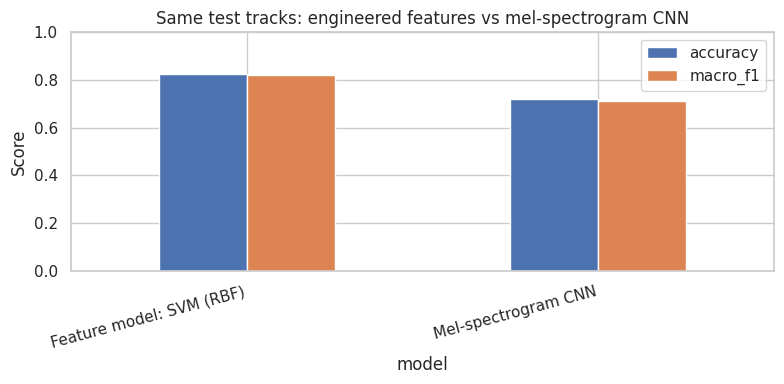

CNN model and result files saved in: /content/outputs/individual_cnn
Download bundle: /content/outputs/individual_cnn_results.zip


In [ ]:
# 2.5D — Learning behaviour, error analysis, and a matched model comparison

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

# CNN learning curves show whether validation performance follows training.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cnn.history["loss"], label="Train")
axes[0].plot(history_cnn.history["val_loss"], label="Validation")
axes[0].set_title("CNN loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[1].plot(history_cnn.history["accuracy"], label="Train")
axes[1].plot(history_cnn.history["val_accuracy"], label="Validation")
axes[1].set_title("CNN crop accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

# Confusion matrix and the most frequent directed error pairs.
cm_cnn = confusion_matrix(
    y_true_cnn, y_pred_cnn, labels=genre_encoder_cnn.classes_
)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    cm_cnn, annot=True, fmt="d", cmap="magma",
    xticklabels=genre_encoder_cnn.classes_,
    yticklabels=genre_encoder_cnn.classes_, ax=ax
)
ax.set_title("Mel-spectrogram CNN — held-out track confusion")
ax.set_xlabel("Predicted genre")
ax.set_ylabel("Actual genre")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

cnn_error_pairs = []
for row, actual in enumerate(genre_encoder_cnn.classes_):
    for col, predicted in enumerate(genre_encoder_cnn.classes_):
        if row != col and cm_cnn[row, col] > 0:
            cnn_error_pairs.append((int(cm_cnn[row, col]), actual, predicted))
cnn_error_pairs.sort(reverse=True)
print("Most frequent CNN errors (actual -> predicted):")
for count, actual, predicted in cnn_error_pairs[:8]:
    print(f"{actual} -> {predicted}: {count} tracks")

# Re-score Part 2's validation-selected 3-second feature model on the exact
# test tracks for which the WAV archive produced readable spectrograms.
matched_comparison = None
if all(name in globals() for name in ["data_3", "test_results", "validation_results", "fitted_models"]):
    selected_rows = validation_results[validation_results["dataset"] == "3_sec"].sort_values(
        ["macro_f1", "accuracy"], ascending=False
    )
    selected_feature_name = str(selected_rows.iloc[0]["model"])
    selected_feature_model = fitted_models[selected_feature_name][0]
    feature_cols_3 = [
        col for col in data_3.select_dtypes(include="number").columns
        if col not in {"length"}
    ]
    feature_test_rows = data_3[
        data_3["track_id"].astype(str).isin(cnn_test_ids_sorted)
    ].copy()
    feature_prob_rows = selected_feature_model.predict_proba(
        feature_test_rows[feature_cols_3].replace([np.inf, -np.inf], np.nan)
    )
    feature_prob_frame = pd.DataFrame(
        feature_prob_rows, columns=selected_feature_model.classes_,
        index=feature_test_rows.index
    )
    feature_prob_frame["track_id"] = feature_test_rows["track_id"].astype(str).values
    feature_track_prob = feature_prob_frame.groupby("track_id")[
        list(selected_feature_model.classes_)
    ].mean()
    common_test_ids = sorted(set(cnn_test_ids_sorted) & set(feature_track_prob.index))
    if common_test_ids:
        common_truth = [true_label_by_track_cnn[track_id] for track_id in common_test_ids]
        feature_pred = feature_track_prob.loc[common_test_ids].idxmax(axis=1).tolist()
        cnn_pred_common = track_prob_cnn.loc[common_test_ids].idxmax(axis=1).tolist()
        matched_comparison = pd.DataFrame([
            {
                "model": f"Feature model: {selected_feature_name}",
                "accuracy": accuracy_score(common_truth, feature_pred),
                "macro_f1": f1_score(common_truth, feature_pred,
                                     labels=genre_encoder_cnn.classes_, average="macro", zero_division=0),
            },
            {
                "model": "Mel-spectrogram CNN",
                "accuracy": accuracy_score(common_truth, cnn_pred_common),
                "macro_f1": f1_score(common_truth, cnn_pred_common,
                                     labels=genre_encoder_cnn.classes_, average="macro", zero_division=0),
            },
        ])
        print(f"Matched comparison uses {len(common_test_ids)} identical held-out tracks.")
        display(matched_comparison.round(3))
        matched_comparison.set_index("model")[["accuracy", "macro_f1"]].plot(
            kind="bar", ylim=(0, 1), figsize=(8, 4),
            title="Same test tracks: engineered features vs mel-spectrogram CNN"
        )
        plt.ylabel("Score")
        plt.xticks(rotation=15, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("No common test tracks were available for the feature-model comparison.")
else:
    print("Part 2 result tables were not found; CNN metrics are still available above.")

# Save reusable model, per-track probabilities, figures, and a compact summary.
cnn_model_path = cnn_output_dir / "mel_spectrogram_cnn.keras"
cnn_model.save(cnn_model_path)
track_prob_cnn.to_csv(cnn_output_dir / "cnn_test_track_probabilities.csv")
pd.DataFrame({"actual": y_true_cnn, "predicted": y_pred_cnn}, index=cnn_test_ids_sorted).to_csv(
    cnn_output_dir / "cnn_test_predictions.csv", index_label="track_id"
)
pd.DataFrame({
    "metric": ["accuracy", "macro_f1", "test_tracks", "valid_audio_tracks"],
    "value": [cnn_accuracy, cnn_macro_f1, len(cnn_test_ids_sorted), len(audio_map)],
}).to_csv(cnn_output_dir / "cnn_summary.csv", index=False)

import shutil
cnn_bundle_path = Path("/content/outputs/individual_cnn_results.zip")
shutil.make_archive(str(cnn_bundle_path.with_suffix("")), "zip", cnn_output_dir)
print(f"CNN model and result files saved in: {cnn_output_dir}")
print(f"Download bundle: {cnn_bundle_path}")


In [ ]:
pd.DataFrame(history_cnn.history)[
    ["loss", "val_loss", "accuracy", "val_accuracy"]
].round(3)

,loss,val_loss,accuracy,val_accuracy
0,1.976,2.326,0.281,0.100
1,1.714,2.466,0.380,0.100
2,1.631,2.708,0.424,0.100
3,1.582,3.040,0.448,0.100
4,1.522,3.325,0.477,0.100
5,1.482,3.485,0.490,0.100
6,1.461,3.460,0.507,0.101
7,1.449,3.394,0.515,0.129
8,1.421,2.968,0.529,0.213
9,1.405,2.550,0.539,0.273


In [1]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_true_cnn = [true_label_by_track_cnn[track_id] for track_id in cnn_test_ids_sorted]
y_pred_cnn = [
    track_prob_cnn.loc[track_id].idxmax()
    for track_id in cnn_test_ids_sorted
]

print(f"CNN test track accuracy: {accuracy_score(y_true_cnn, y_pred_cnn):.3f}")
print(f"CNN test macro-F1: {f1_score(y_true_cnn, y_pred_cnn, average='macro'):.3f}")
print(classification_report(y_true_cnn, y_pred_cnn, zero_division=0))vvv

CNN misclassified 56 of 199 test songs.
Sample misclassified songs:


,track_id,actual_genre,predicted_genre,top_prediction,second_prediction
0,blues.00056,blues,country,country (24.6%),blues (20.0%)
1,blues.00072,blues,country,country (42.6%),rock (13.6%)
2,blues.00099,blues,classical,classical (28.4%),blues (24.4%)
3,classical.00080,classical,jazz,jazz (56.6%),classical (37.5%)
4,country.00023,country,blues,blues (31.3%),classical (27.1%)
5,country.00030,country,classical,classical (61.8%),blues (15.0%)
6,country.00043,country,rock,rock (31.7%),country (20.4%)
7,country.00048,country,blues,blues (37.7%),country (22.1%)
8,country.00050,country,rock,rock (27.7%),country (21.6%)
9,country.00053,country,disco,disco (25.8%),rock (20.6%)


Most frequent genre confusions:


,actual_genre,predicted_genre,number_of_songs
0,rock,disco,5
1,rock,country,4
2,hiphop,pop,3
3,disco,hiphop,3
4,disco,reggae,3
5,jazz,classical,3
6,rock,reggae,3
7,pop,disco,2
8,jazz,country,2
9,country,rock,2


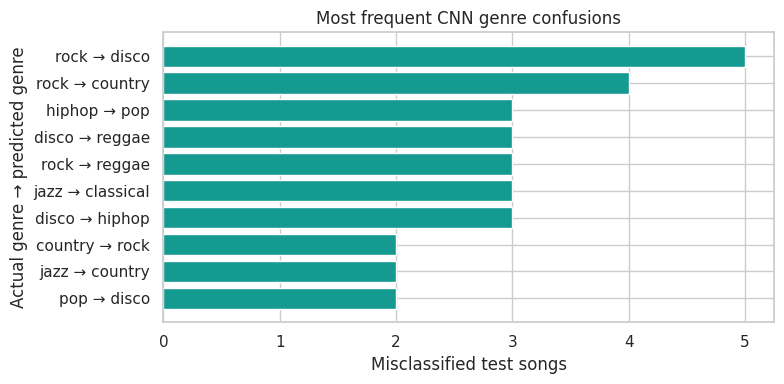

In [ ]:
# CNN error analysis: inspect mistakes on held-out test songs

error_rows = []

for track_id in cnn_test_ids_sorted:
    actual = true_label_by_track_cnn[track_id]
    probabilities = track_prob_cnn.loc[track_id].sort_values(ascending=False)
    predicted = probabilities.index[0]

    if predicted != actual:
        error_rows.append({
            "track_id": track_id,
            "actual_genre": actual,
            "predicted_genre": predicted,
            "top_prediction": f"{predicted} ({probabilities.iloc[0] * 100:.1f}%)",
            "second_prediction": (
                f"{probabilities.index[1]} ({probabilities.iloc[1] * 100:.1f}%)"
            ),
        })

errors_df = pd.DataFrame(error_rows)

if errors_df.empty:
    print("The CNN made no errors on this test set.")
else:
    print(f"CNN misclassified {len(errors_df)} of {len(cnn_test_ids_sorted)} test songs.")
    print("Sample misclassified songs:")
    display(errors_df.head(10))

    confusion_pairs = (
        errors_df.groupby(["actual_genre", "predicted_genre"])
        .size()
        .sort_values(ascending=False)
        .rename("number_of_songs")
        .reset_index()
    )

    print("Most frequent genre confusions:")
    display(confusion_pairs.head(10))

    plot_data = confusion_pairs.head(10).sort_values("number_of_songs")
    plt.figure(figsize=(8, 4))
    plt.barh(
        plot_data["actual_genre"] + " → " + plot_data["predicted_genre"],
        plot_data["number_of_songs"],
        color="#159A91"
    )
    plt.xlabel("Misclassified test songs")
    plt.ylabel("Actual genre → predicted genre")
    plt.title("Most frequent CNN genre confusions")
    plt.tight_layout()
    plt.show()

Held-out song: blues.00056
Actual genre: blues | CNN prediction: country


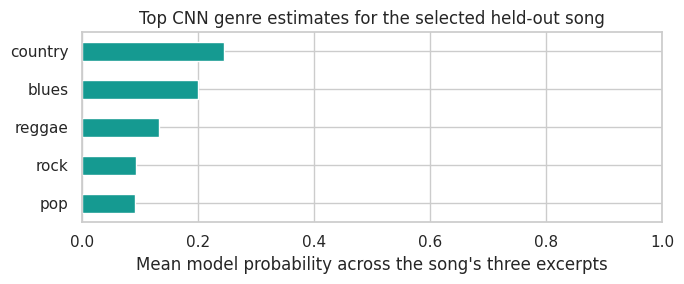

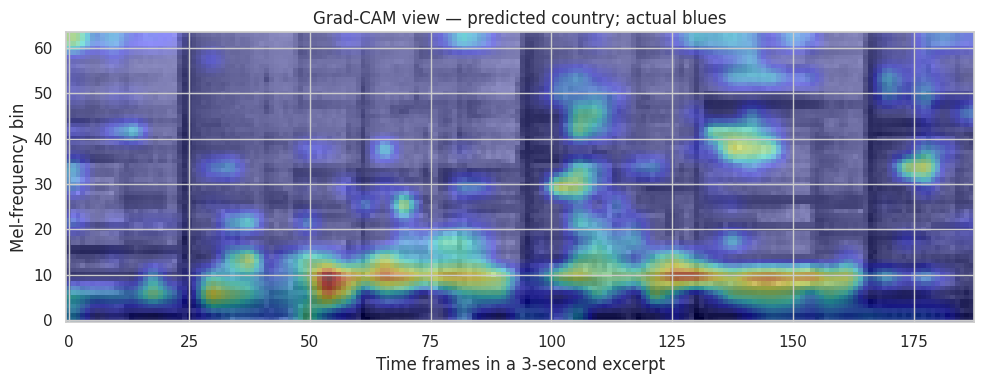

In [ ]:
# 2.5E — Play a held-out song and inspect its CNN probability estimates
# Click play in the audio player. The example is selected from the CNN test split.

from IPython.display import Audio, display

if cnn_error_pairs:
    interesting_ids = [
        track_id for track_id in cnn_test_ids_sorted
        if true_label_by_track_cnn[track_id] != track_prob_cnn.loc[track_id].idxmax()
    ]
else:
    interesting_ids = []

probe_track_id = interesting_ids[0] if interesting_ids else cnn_test_ids_sorted[0]
probe_path = audio_map[probe_track_id]
probe_true = true_label_by_track_cnn[probe_track_id]
probe_probs = track_prob_cnn.loc[probe_track_id].sort_values(ascending=False)
probe_pred = probe_probs.index[0]

print(f"Held-out song: {probe_track_id}")
print(f"Actual genre: {probe_true} | CNN prediction: {probe_pred}")
display(Audio(filename=str(probe_path)))
probe_probs.head(5).sort_values().plot(kind="barh", color="#159A91", figsize=(7, 3))
plt.xlim(0, 1)
plt.xlabel("Mean model probability across the song's three excerpts")
plt.title("Top CNN genre estimates for the selected held-out song")
plt.tight_layout()
plt.show()

# Grad-CAM highlights spectrogram regions associated with the predicted class.
# Treat it as a model-inspection visualization, not proof of musical causation.
# Grad-CAM highlights spectrogram regions associated with the predicted class.
# It is a model-inspection visualization, not proof of musical causation.

probe_indices = np.flatnonzero(crop_track_ids_cnn == probe_track_id)
probe_spec = X_cnn[probe_indices[0]:probe_indices[0] + 1]

# Rebuild the model graph explicitly so Keras can access conv3's activations.
grad_input = tf.keras.Input(shape=cnn_model.input_shape[1:])
x = grad_input
conv_activations = None

for layer in cnn_model.layers:
    if isinstance(layer, tf.keras.layers.InputLayer):
        continue
    x = layer(x)
    if layer.name == "conv3":
        conv_activations = x

if conv_activations is None:
    raise ValueError("Could not find the CNN layer named 'conv3'.")

grad_model_cnn = tf.keras.Model(
    inputs=grad_input,
    outputs=[conv_activations, x]
)

with tf.GradientTape() as tape:
    activations, outputs = grad_model_cnn(probe_spec, training=False)
    class_index = int(tf.argmax(outputs[0]))
    target_score = outputs[:, class_index]

gradients = tape.gradient(target_score, activations)
weights_cam = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
cam = tf.reduce_sum(weights_cam * activations, axis=-1)
cam = tf.nn.relu(cam)
cam = cam / (
    tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8
)
cam = tf.image.resize(
    cam[..., tf.newaxis],
    (N_MELS_CNN, TARGET_FRAMES_CNN)
)[0, :, :, 0].numpy()

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(probe_spec[0, :, :, 0], origin="lower", aspect="auto", cmap="gray_r")
ax.imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.42)
ax.set_title(f"Grad-CAM view — predicted {probe_pred}; actual {probe_true}")
ax.set_xlabel("Time frames in a 3-second excerpt")
ax.set_ylabel("Mel-frequency bin")
plt.tight_layout()
plt.show()


In [ ]:
# PART 3 — Similar-song recommender
#This part scales the audio features and uses cosine similarity to find songs with feature patterns similar to a selected dataset track. It demonstrates a simple recommendation use for the audio-feature data.
# Run after Part 1 in the same Colab runtime.

from pathlib import Path
import sqlite3
import zipfile

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

DB_PATH = Path("/content/outputs/part1/music_genre.db")
OUTPUT_DIR = Path("/content/outputs/part3")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    raise FileNotFoundError("Run Part 1 first; its SQLite database was not found.")

# Use one row per original song.
with sqlite3.connect(DB_PATH) as connection:
    songs = pd.read_sql_query("SELECT * FROM features_30_sec", connection)

# Use numeric audio features; exclude identifiers and metadata.
excluded = {"length", "track_id"}
feature_cols = [
    col for col in songs.select_dtypes(include="number").columns
    if col not in excluded
]
if not feature_cols:
    raise ValueError("No numeric audio features were found.")

# Impute any missing feature values, then scale features before comparing them.
X = songs[feature_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X)

# Similarity matrix: each row corresponds to one song.
similarities = cosine_similarity(X_scaled)

print(f"Loaded {len(songs)} tracks and {len(feature_cols)} audio features.")
print("Enter a dataset filename (for example, blues.00000.wav) or track ID.")

query = input("Track to find similar songs for: ").strip().lower()
if not query:
    raise ValueError("Enter a filename or track ID.")

# Match filename or original track ID.
filenames = songs["filename"].astype(str).str.lower()
track_ids = songs["track_id"].astype(str).str.lower()
matches = songs.index[
    filenames.str.contains(query, regex=False) |
    track_ids.str.contains(query, regex=False)
].tolist()

if len(matches) == 0:
    raise ValueError(
        f"No dataset track matched '{query}'. Try a filename such as blues.00000.wav."
    )
if len(matches) > 1:
    examples = songs.loc[matches[:10], ["filename", "label"]]
    print("That search matched multiple tracks. Try one exact filename:")
    display(examples)
    raise ValueError("Rerun this cell with a more specific filename.")

target_index = matches[0]
target = songs.loc[target_index]

# Sort by similarity and exclude the selected song itself.
scores = similarities[target_index]
ranked_indices = np.argsort(scores)[::-1]
ranked_indices = [
    index for index in ranked_indices
    if index != target_index
][:10]

recommendations = songs.loc[
    ranked_indices, ["filename", "label"]
].copy()
recommendations.insert(
    0, "similarity", [float(scores[index]) for index in ranked_indices]
)
recommendations.insert(0, "query_track", target["filename"])

print(f"\nSimilar tracks to {target['filename']} ({target['label']}):")
display(recommendations)

csv_path = OUTPUT_DIR / "similar_songs.csv"
recommendations.to_csv(csv_path, index=False)

zip_path = OUTPUT_DIR / "part3_results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(csv_path, arcname="similar_songs.csv")

print(f"Saved recommendations: {csv_path}")
files.download(str(zip_path))

Loaded 1000 tracks and 57 audio features.
Enter a dataset filename (for example, blues.00000.wav) or track ID.
Track to find similar songs for: disco.00000.wav

Similar tracks to disco.00000.wav (disco):


,query_track,similarity,filename,label
345,disco.00000.wav,0.718502,disco.00045.wav,disco
855,disco.00000.wav,0.661387,reggae.00055.wav,reggae
317,disco.00000.wav,0.648878,disco.00017.wav,disco
452,disco.00000.wav,0.642552,hiphop.00052.wav,hiphop
470,disco.00000.wav,0.629959,hiphop.00070.wav,hiphop
465,disco.00000.wav,0.601847,hiphop.00065.wav,hiphop
942,disco.00000.wav,0.598965,rock.00042.wav,rock
451,disco.00000.wav,0.595959,hiphop.00051.wav,hiphop
849,disco.00000.wav,0.589791,reggae.00049.wav,reggae
952,disco.00000.wav,0.589250,rock.00052.wav,rock


Saved recommendations: /content/outputs/part3/similar_songs.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload one .wav file or a .zip file containing a .wav file.


Saving blues.00000.wav.zip to blues.00000.wav (1).zip
Extracting features from audio window 1...

Audio file: blues.00000.wav
Predicted genre: blues
Model probability estimate: 95.2%
This is the model's estimate, not a guarantee and not a score derived from the confusion matrix.


,genre,probability_percent
0,blues,95.218641
2,country,1.595859
3,disco,1.375999
5,jazz,1.102232
9,rock,0.591998
1,classical,0.067900
4,hiphop,0.038446
8,reggae,0.006620
6,metal,0.002115
7,pop,0.000190


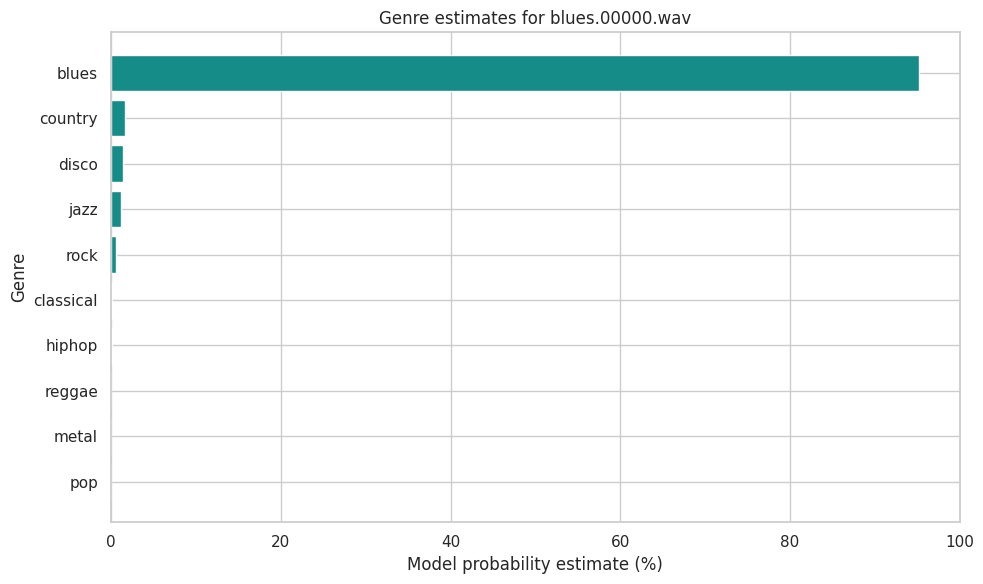


Saved results in: /content/outputs/part4


In [ ]:
# PART 4 — Upload an audio track and predict its genre
#This part accepts an audio file, extracts features, and uses the trained model to estimate its genre. The displayed probabilities are the model’s estimates for that file; they are not overall accuracy scores or guarantees
# Run after Part 2 in the same Colab runtime.
# If you get "No module named librosa", first run:
# !pip -q install librosa

from pathlib import Path, PurePosixPath
import zipfile

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

MODEL_DIR = Path("/content/outputs/part2")
MODEL_PATH = MODEL_DIR / "30_sec_best_model.joblib"
OUTPUT_DIR = Path("/content/outputs/part4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 22050
WINDOW_SECONDS = 30


def load_saved_model():
    """Use Part 2's model, or upload its results ZIP if needed."""
    global MODEL_PATH

    if MODEL_PATH.exists():
        return joblib.load(MODEL_PATH)

    print("Upload part2_results.zip, or the 30_sec_best_model.joblib file.")
    uploaded = files.upload()

    for filename in uploaded:
        file_path = Path("/content") / filename

        if filename.lower().endswith(".joblib"):
            MODEL_DIR.mkdir(parents=True, exist_ok=True)
            MODEL_PATH.write_bytes(file_path.read_bytes())
            return joblib.load(MODEL_PATH)

        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(file_path) as archive:
                model_members = [
                    name for name in archive.namelist()
                    if name.lower().endswith("30_sec_best_model.joblib")
                ]
                if model_members:
                    MODEL_DIR.mkdir(parents=True, exist_ok=True)
                    MODEL_PATH.write_bytes(archive.read(model_members[0]))
                    return joblib.load(MODEL_PATH)

    raise FileNotFoundError(
        "Could not find 30_sec_best_model.joblib. "
        "Upload the model file or the Part 2 results ZIP."
    )


def upload_wav():
    """Upload a WAV directly, or upload a ZIP containing one WAV."""
    print("Upload one .wav file or a .zip file containing a .wav file.")
    uploaded = files.upload()

    for filename in uploaded:
        file_path = Path("/content") / filename
        if filename.lower().endswith(".wav"):
            return file_path

    for filename in uploaded:
        file_path = Path("/content") / filename
        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(file_path) as archive:
                wav_members = [
                    name for name in archive.namelist()
                    if name.lower().endswith(".wav")
                ]
                if not wav_members:
                    continue

                member = wav_members[0]
                output_path = Path("/content") / PurePosixPath(member).name
                output_path.write_bytes(archive.read(member))
                return output_path

    raise ValueError("No WAV file was found in the upload.")


def extract_gtzan_features(audio, sample_rate):
    """Extract the 57 numeric GTZAN-style features expected by Part 2."""
    features = {}

    feature_arrays = {
        "chroma_stft": librosa.feature.chroma_stft(y=audio, sr=sample_rate),
        "rms": librosa.feature.rms(y=audio),
        "spectral_centroid": librosa.feature.spectral_centroid(
            y=audio, sr=sample_rate
        ),
        "spectral_bandwidth": librosa.feature.spectral_bandwidth(
            y=audio, sr=sample_rate
        ),
        "rolloff": librosa.feature.spectral_rolloff(
            y=audio, sr=sample_rate
        ),
        "zero_crossing_rate": librosa.feature.zero_crossing_rate(audio),
    }

    harmonic, percussive = librosa.effects.hpss(audio)
    feature_arrays["harmony"] = harmonic
    feature_arrays["perceptr"] = percussive

    for feature_name, values in feature_arrays.items():
        features[f"{feature_name}_mean"] = float(np.mean(values))
        features[f"{feature_name}_var"] = float(np.var(values))

    # Compatibility with librosa versions that expose tempo in different places.
    if hasattr(librosa.feature, "tempo"):
        tempo_values = librosa.feature.tempo(y=audio, sr=sample_rate)
    else:
        tempo_values = librosa.beat.tempo(y=audio, sr=sample_rate)

    features["tempo"] = float(np.asarray(tempo_values).reshape(-1)[0])

    mfccs = librosa.feature.mfcc(
        y=audio, sr=sample_rate, n_mfcc=20
    )
    for number, coefficient in enumerate(mfccs, start=1):
        features[f"mfcc{number}_mean"] = float(np.mean(coefficient))
        features[f"mfcc{number}_var"] = float(np.var(coefficient))

    return features


def make_audio_windows(audio_path):
    """Load mono audio and split it into windows for the 30-second model."""
    audio, sample_rate = librosa.load(
        audio_path, sr=SAMPLE_RATE, mono=True
    )

    if len(audio) < sample_rate * 5:
        raise ValueError(
            "The audio is shorter than 5 seconds. Please upload a longer clip."
        )

    window_size = sample_rate * WINDOW_SECONDS
    windows = []

    for start in range(0, len(audio), window_size):
        chunk = audio[start:start + window_size]

        # Ignore a very short leftover segment at the end of a long file.
        if len(chunk) < sample_rate * 5:
            continue

        # Pad a shorter final segment so it matches the model's 30-second input.
        if len(chunk) < window_size:
            chunk = np.pad(chunk, (0, window_size - len(chunk)))

        windows.append(chunk)

    if not windows:
        chunk = np.pad(audio, (0, max(0, window_size - len(audio))))
        windows = [chunk[:window_size]]

    return windows


# Load the trained model and upload the audio.
model_bundle = load_saved_model()
model = model_bundle["model"]
feature_names = list(model_bundle["features"])
genre_names = list(model_bundle["genres"])

audio_path = upload_wav()
audio_windows = make_audio_windows(audio_path)

# Extract features from every window, in the exact column order used by Part 2.
window_features = []
for window_number, audio_window in enumerate(audio_windows, start=1):
    print(f"Extracting features from audio window {window_number}...")
    extracted = extract_gtzan_features(audio_window, SAMPLE_RATE)
    window_features.append(extracted)

X_audio = pd.DataFrame(window_features).reindex(
    columns=feature_names
)

# Average probability estimates across windows for one song-level result.
window_probabilities = model.predict_proba(X_audio)
average_probabilities = window_probabilities.mean(axis=0)

probability_table = pd.DataFrame({
    "genre": model.classes_,
    "probability": average_probabilities,
}).sort_values("probability", ascending=False)

predicted_genre = probability_table.iloc[0]["genre"]
confidence_estimate = probability_table.iloc[0]["probability"]

print(f"\nAudio file: {audio_path.name}")
print(f"Predicted genre: {predicted_genre}")
print(f"Model probability estimate: {confidence_estimate:.1%}")
print(
    "This is the model's estimate, not a guarantee and not a score "
    "derived from the confusion matrix."
)

probability_table["probability_percent"] = (
    probability_table["probability"] * 100
)
display(probability_table[["genre", "probability_percent"]])

# Plot the model's probability estimate for each genre.
plt.figure(figsize=(10, 6))
plt.barh(
    probability_table["genre"][::-1],
    probability_table["probability_percent"][::-1],
    color="#168c88",
)
plt.xlabel("Model probability estimate (%)")
plt.ylabel("Genre")
plt.title(f"Genre estimates for {audio_path.name}")
plt.xlim(0, 100)
plt.tight_layout()

chart_path = OUTPUT_DIR / "genre_probability_estimates.png"
plt.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Save the prediction and probability table.
probability_table.to_csv(
    OUTPUT_DIR / "genre_probability_estimates.csv",
    index=False,
)
print(f"\nSaved results in: {OUTPUT_DIR}")